In [6]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from transformers import AutoTokenizer

ATTN_ROOT = "./outputs"   

MODELS = {
    "600M":  "facebook/nllb-200-distilled-600M",
    "1.3B":  "facebook/nllb-200-distilled-1.3B",
    "3.3B":  "facebook/nllb-200-3.3B",          
}

tokenizers = {}
for key, name in MODELS.items():
    tokenizers[key] = AutoTokenizer.from_pretrained(name)
    print(f"Loaded tokenizer: {key}")

Loaded tokenizer: 600M
Loaded tokenizer: 1.3B
Loaded tokenizer: 3.3B


In [7]:
def plot_head(
    src_lang:  str,
    tgt_lang:  str,
    sent_id:   int,
    layer:     int,
    head:      int,
    model:     str   = "600M",
    src_text:  str   = None,
    normalize: bool  = True,
    figsize:   tuple = (12, 6),
    save             = None,    
    dpi:       int   = 150,
):
    model_slug = MODELS[model].split("/")[-1]
    pt_path = (
        Path(ATTN_ROOT)
        / model_slug
        / "attentions"
        / f"{src_lang}-{tgt_lang}"
        / f"{src_lang}-{tgt_lang}-{sent_id}.pt"
    )
    if not pt_path.exists():
        raise FileNotFoundError(f"Not found: {pt_path}")

    attn = torch.load(pt_path, map_location="cpu")   # [L, H, T, S]
    mat  = attn[layer, head].float().numpy()          # [T, S]

    if normalize:
        mat = mat / (mat.sum(axis=-1, keepdims=True) + 1e-8)

    if src_text is not None:
        tok = tokenizers[model]
        tok.src_lang = src_lang
        ids = tok(src_text, return_tensors="pt")["input_ids"][0]
        src_tokens = tok.convert_ids_to_tokens(ids)
    else:
        src_tokens = None

    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(mat, aspect="auto", cmap="viridis", interpolation="nearest")
    plt.colorbar(im, ax=ax, fraction=0.02, pad=0.02)

    if src_tokens is not None:
        ax.set_xticks(range(len(src_tokens)))
        ax.set_xticklabels(src_tokens, rotation=45, ha="right", fontsize=8)

    ax.set_xlabel("Source position", fontsize=11)
    ax.set_ylabel("Generation step",  fontsize=11)
    ax.set_title(
        f"[{model}]  {src_lang} → {tgt_lang}  |  sent {sent_id}  |  L{layer:02d} H{head:02d}",
        fontsize=12,
    )
    plt.tight_layout()

    if save is not None:
        if save is True:
            save = f"./results/maps/{model}-{src_lang}-{tgt_lang}_L{layer:02d}_H{head:02d}-S{sent_id}.png"
        os.makedirs(os.path.dirname(save), exist_ok=True)
        plt.savefig(save, dpi=dpi, bbox_inches="tight")
        print(f"Saved → {save}")

    plt.show()

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S9.png


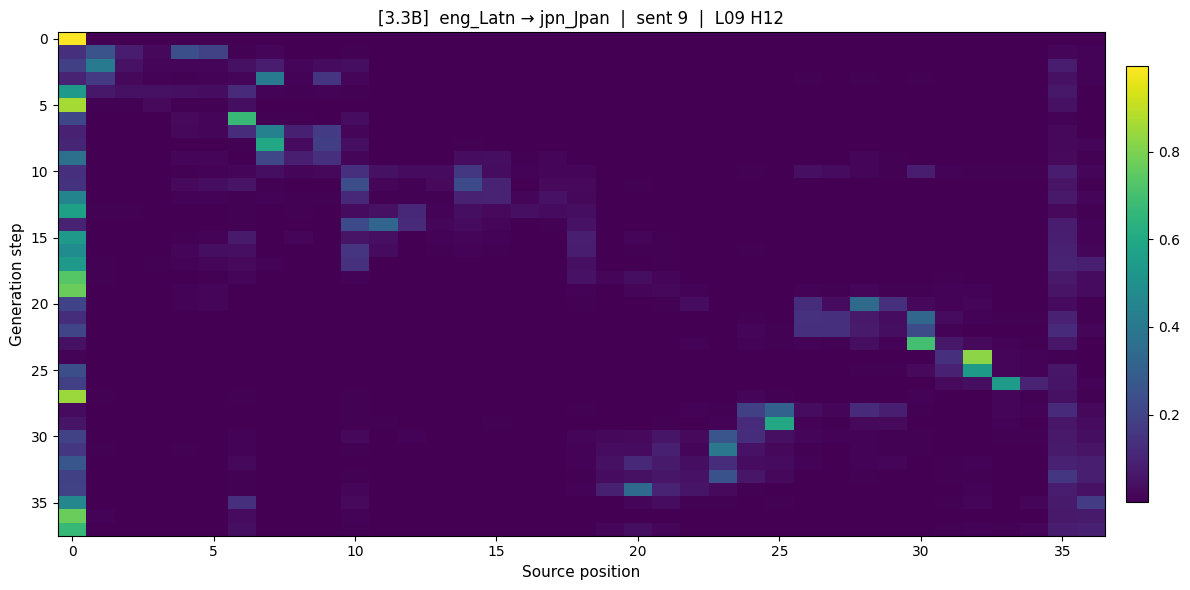

In [8]:
# ── Пример ───────────────────────────────────────────────────────────────────
plot_head(
    src_lang  = "eng_Latn",
    tgt_lang  = "jpn_Jpan",
    sent_id   = 9,
    layer     = 9,
    head      = 12,
    model     = "3.3B",
    src_text  = None,
    save = True,
)

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S9.png


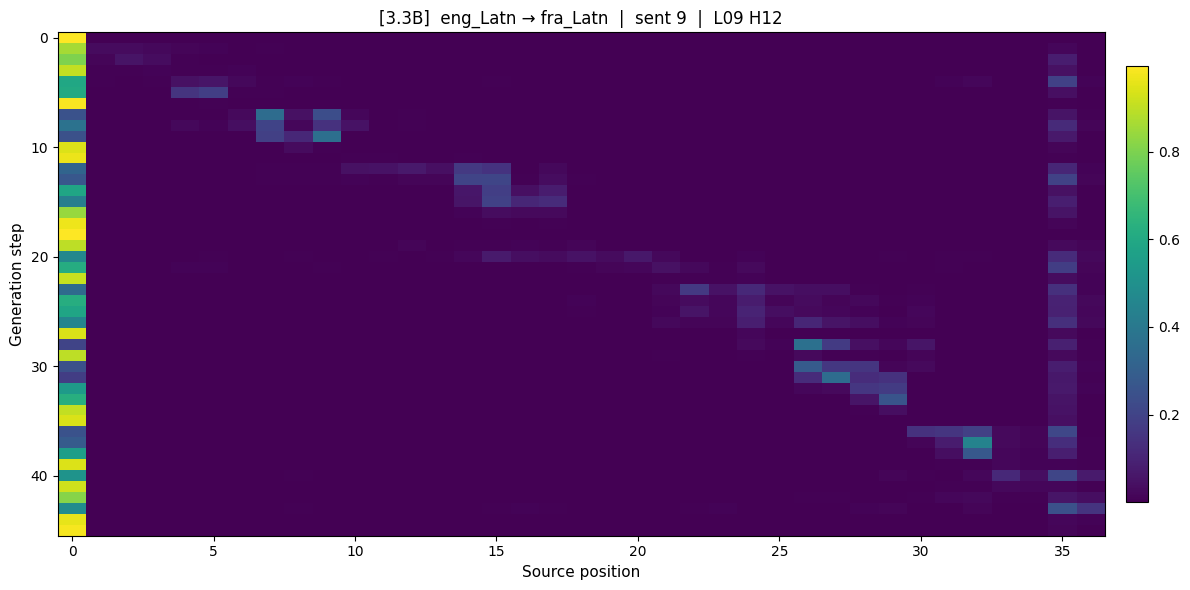

In [9]:
# ── Пример ───────────────────────────────────────────────────────────────────
plot_head(
    src_lang  = "eng_Latn",
    tgt_lang  = "fra_Latn",
    sent_id   = 9,
    layer     = 9,
    head      = 12,
    model     = "3.3B",
    src_text  = None,
    save = True,
)

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S0.png


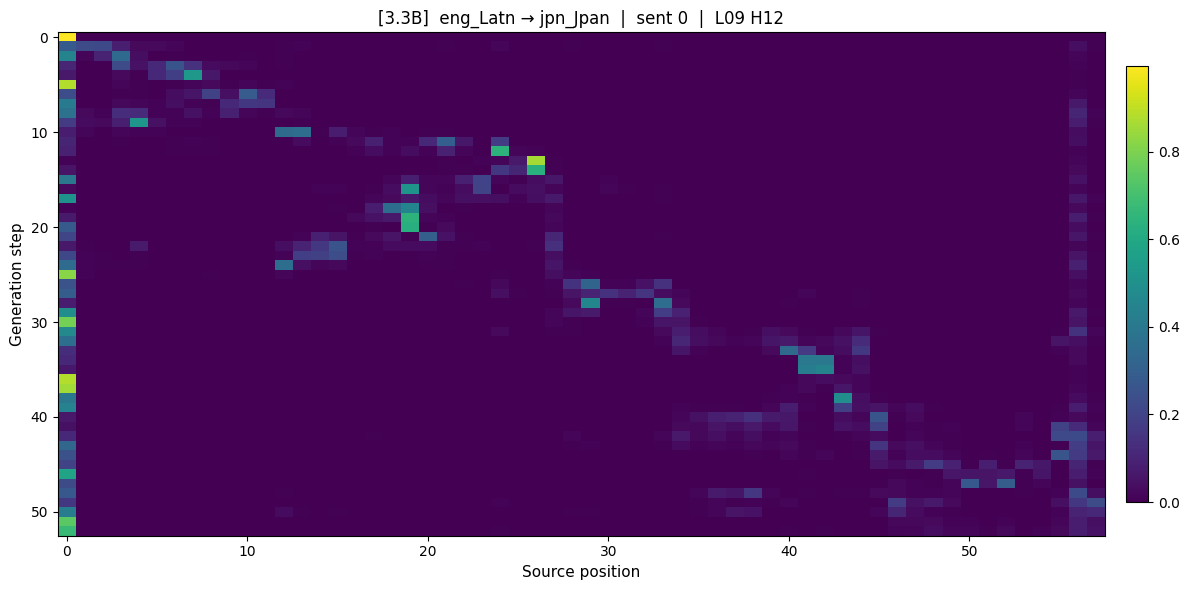

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S0.png


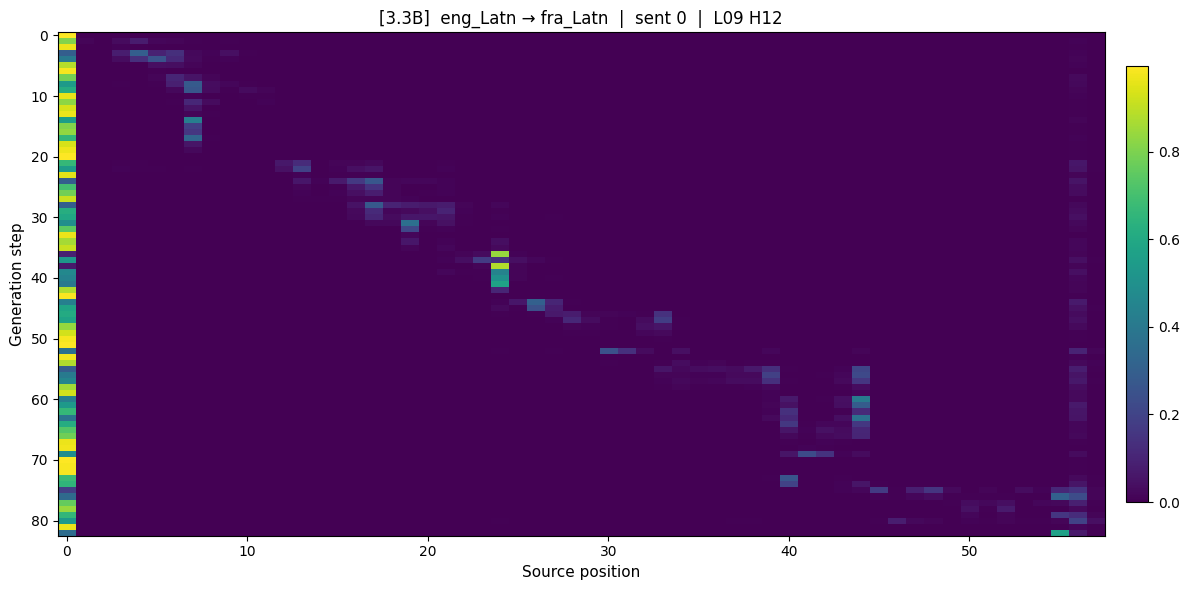

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S1.png


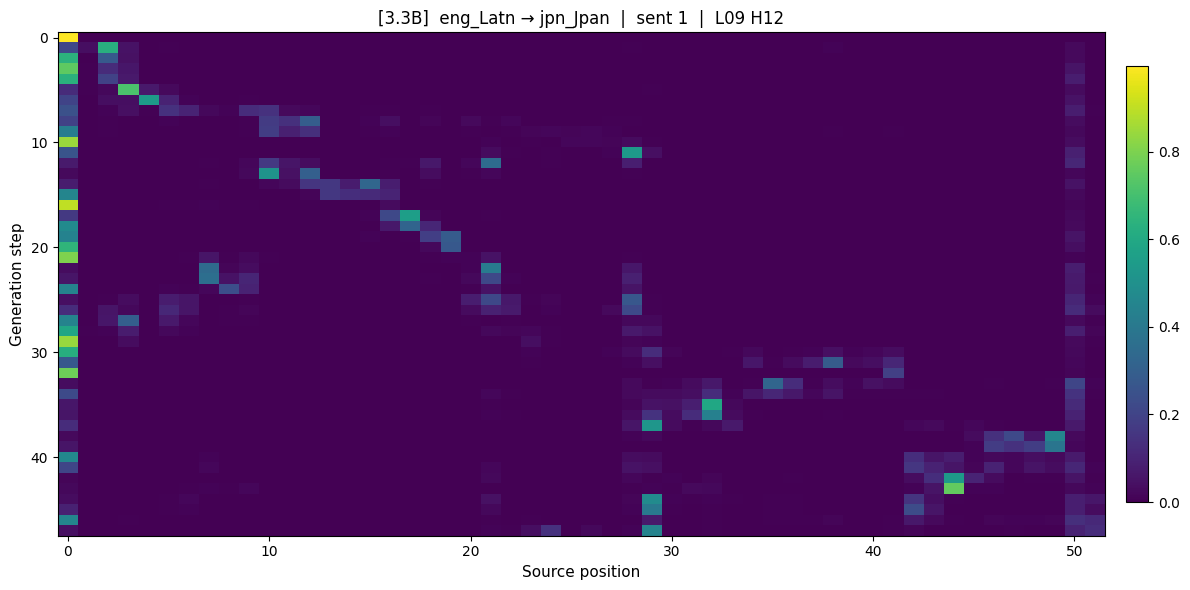

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S1.png


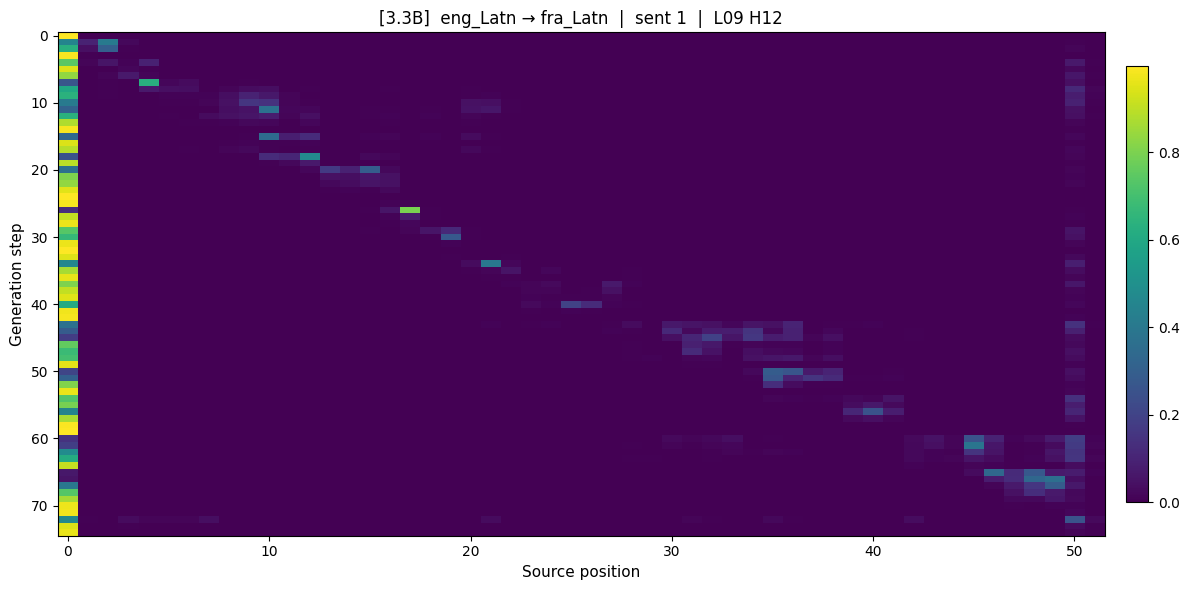

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S2.png


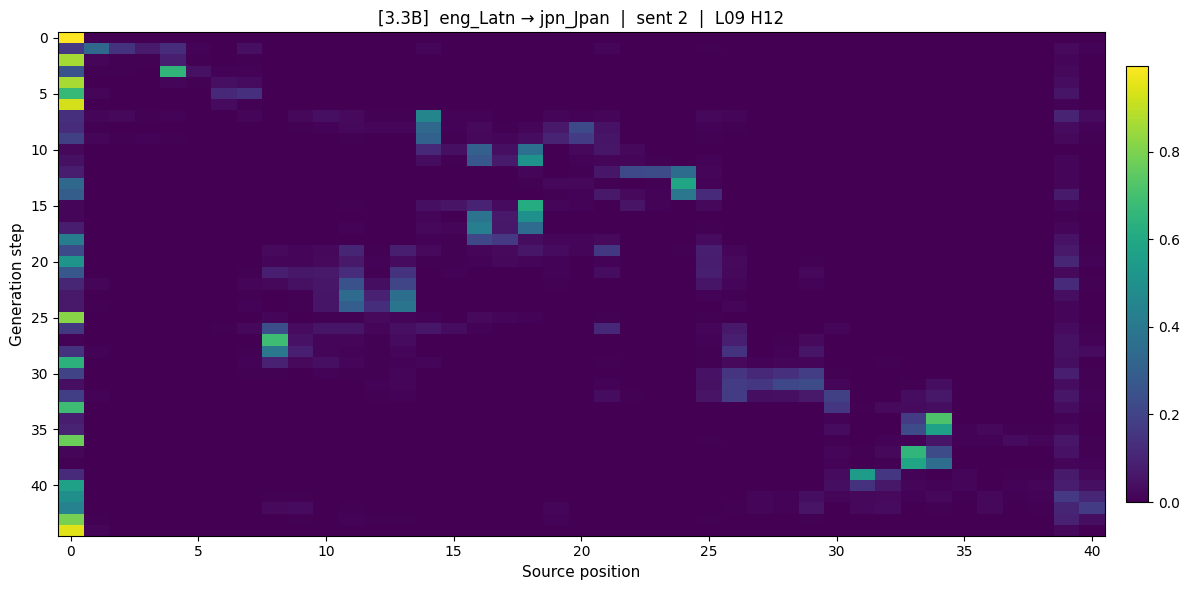

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S2.png


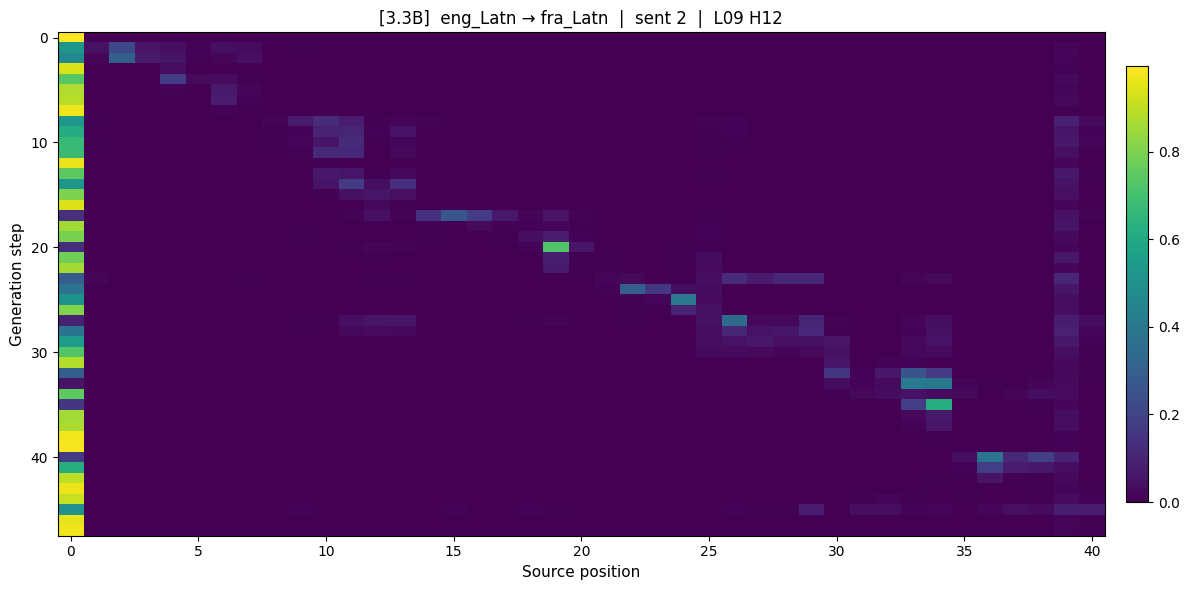

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S3.png


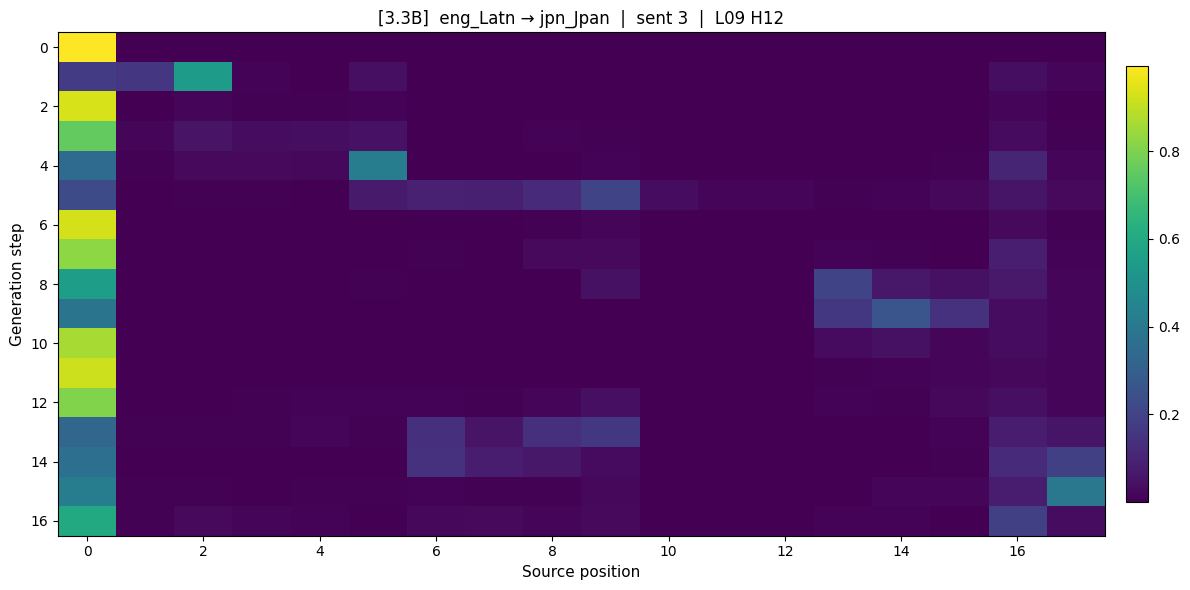

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S3.png


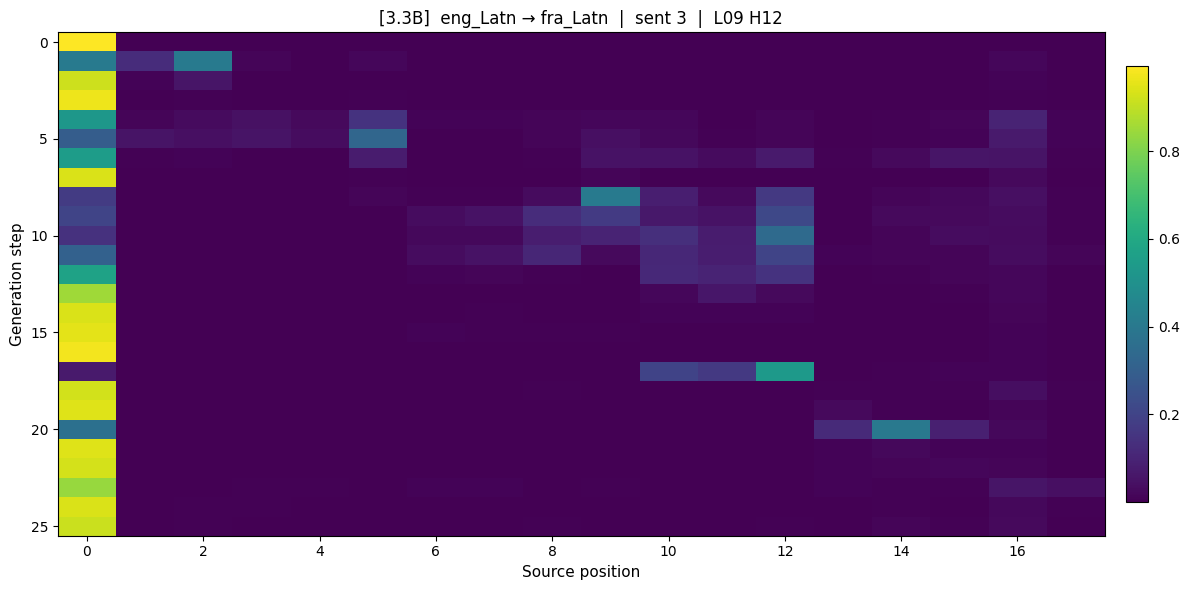

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S4.png


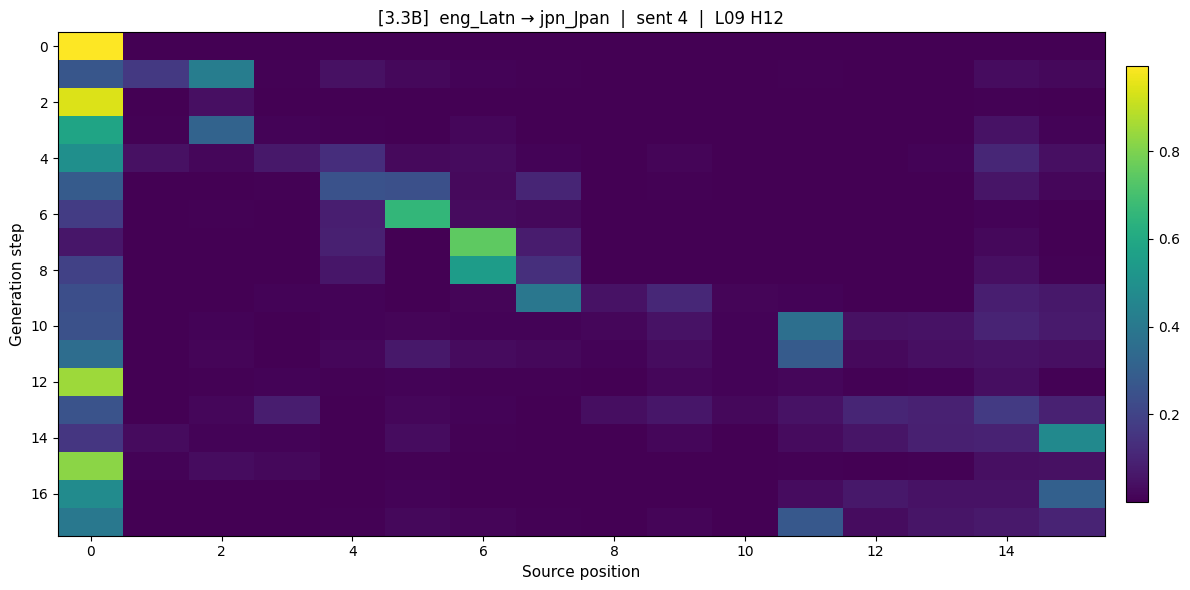

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S4.png


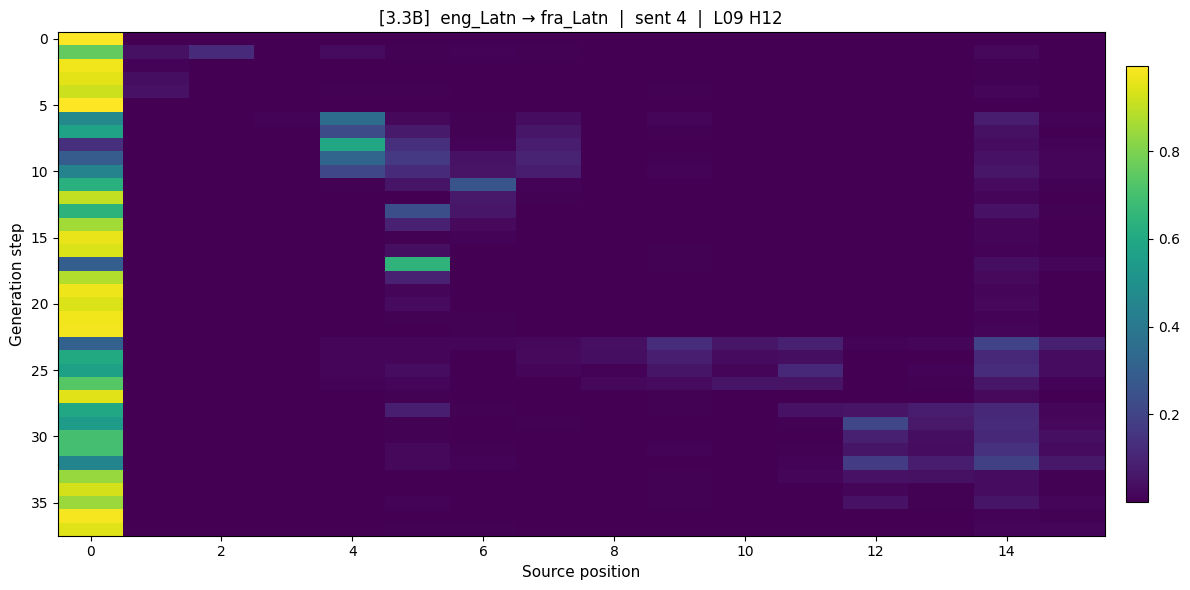

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S5.png


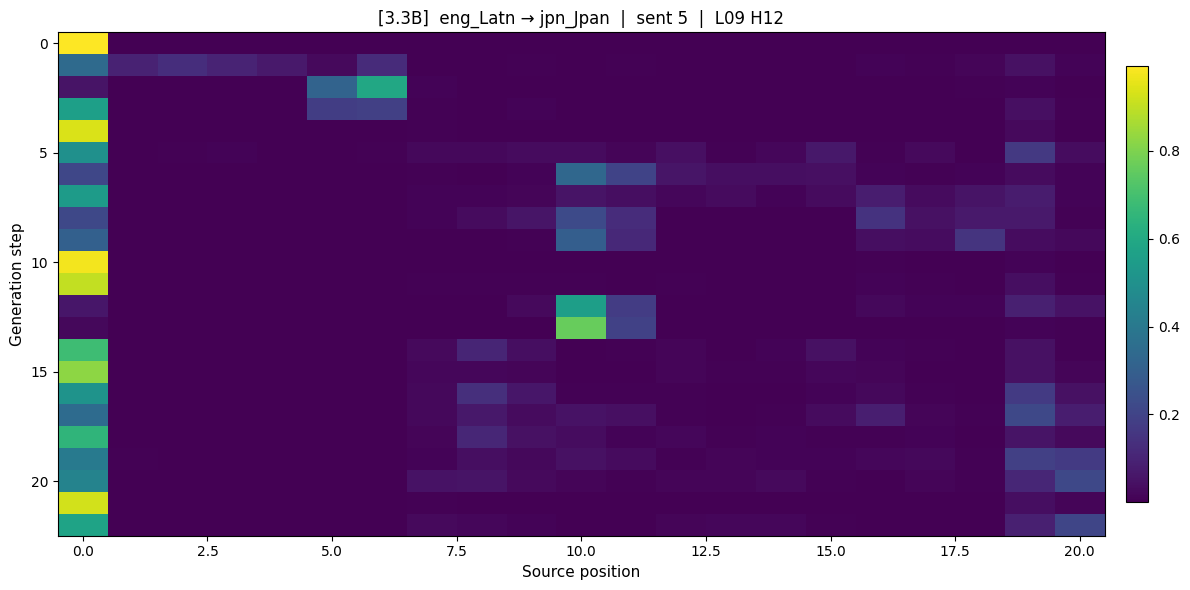

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S5.png


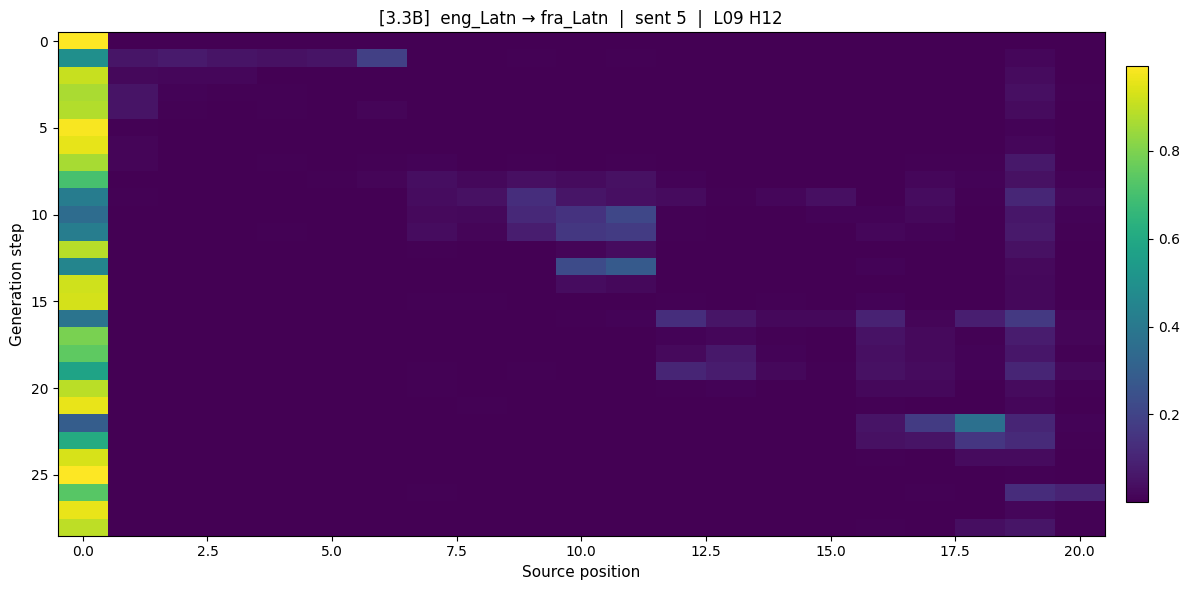

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S6.png


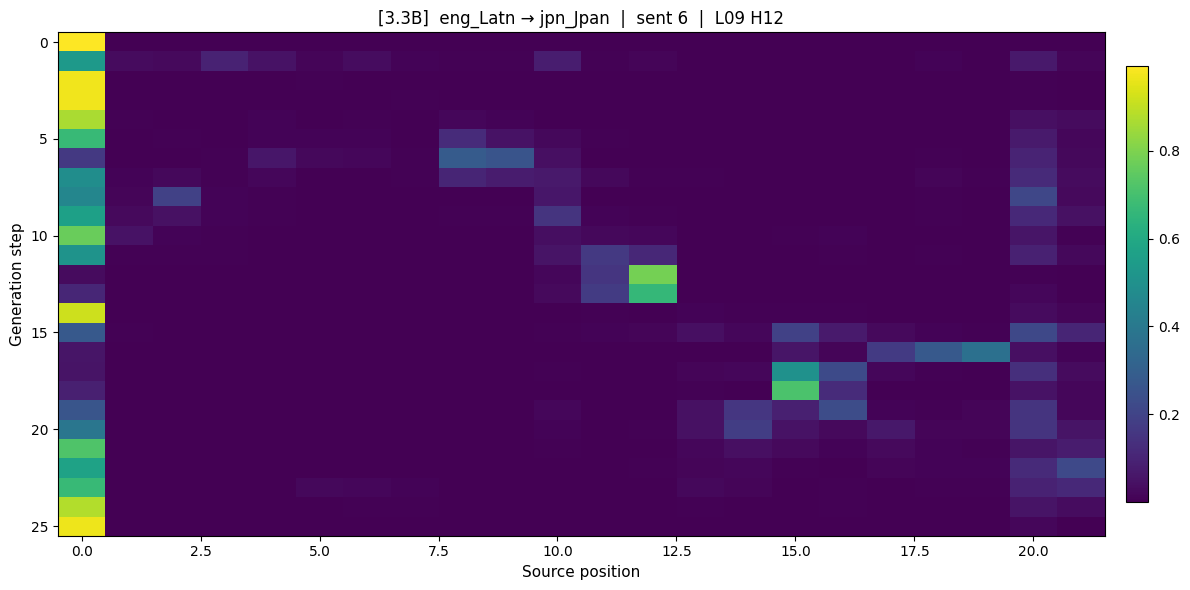

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S6.png


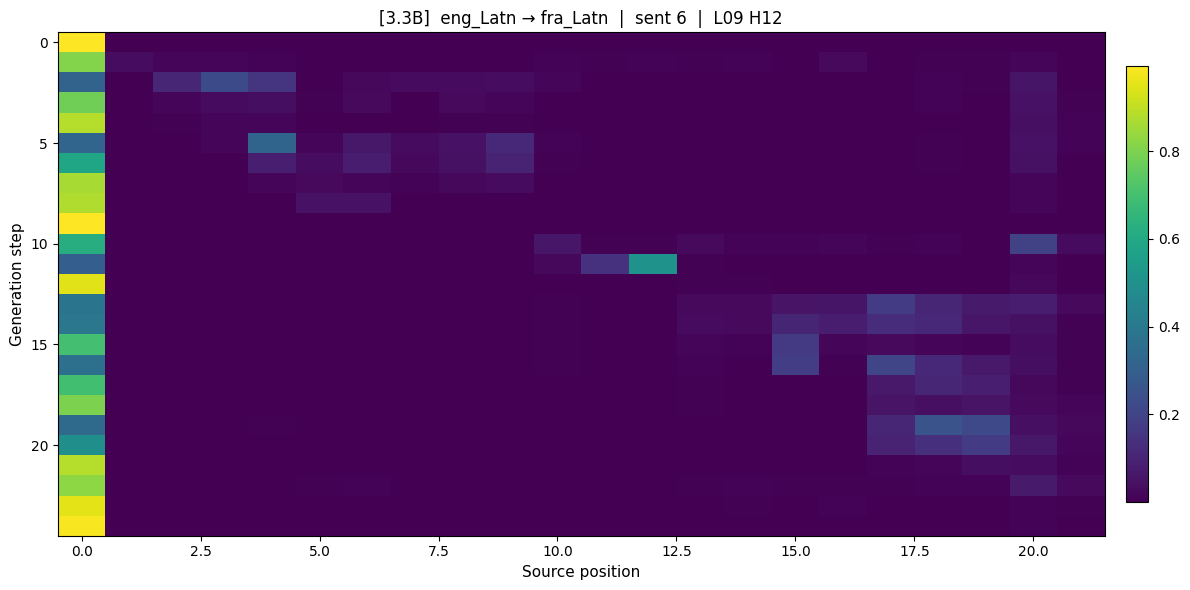

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S7.png


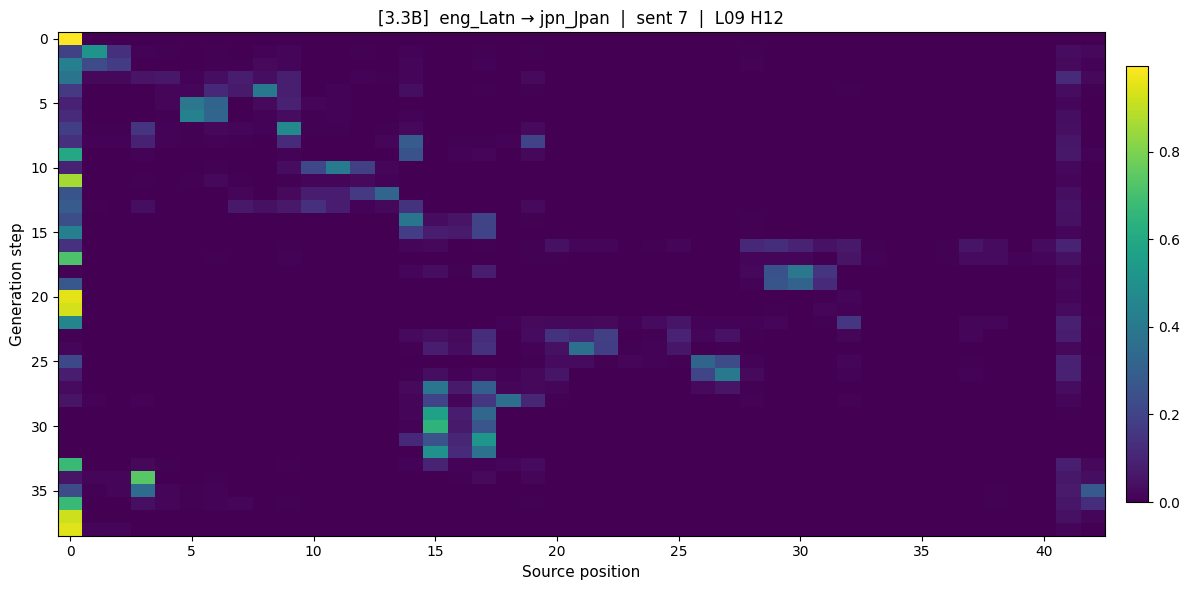

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S7.png


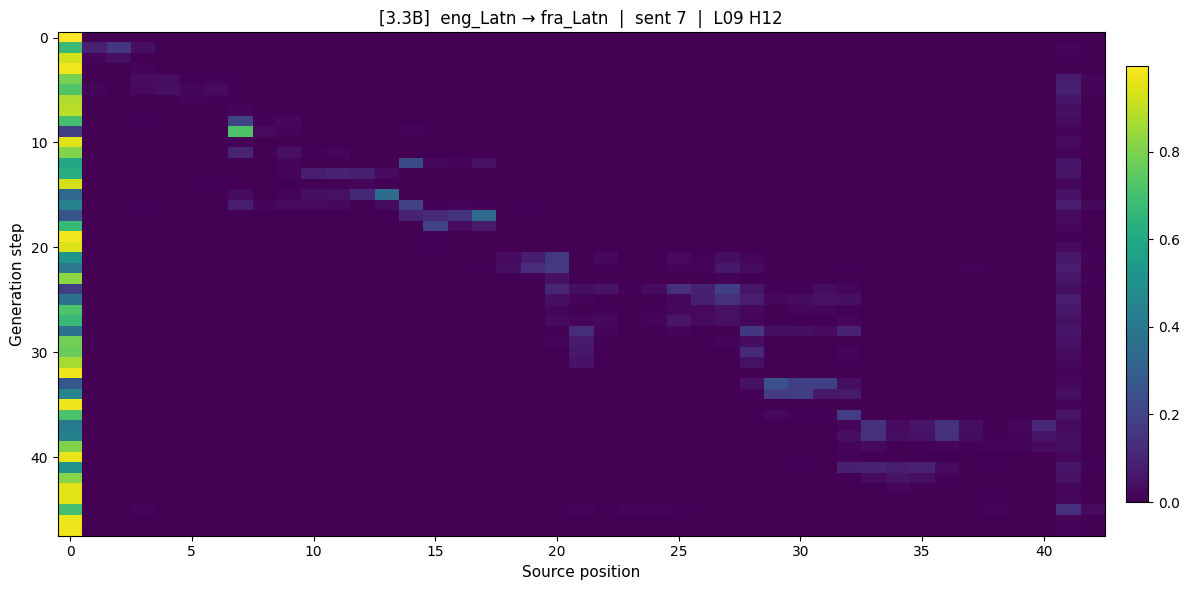

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S8.png


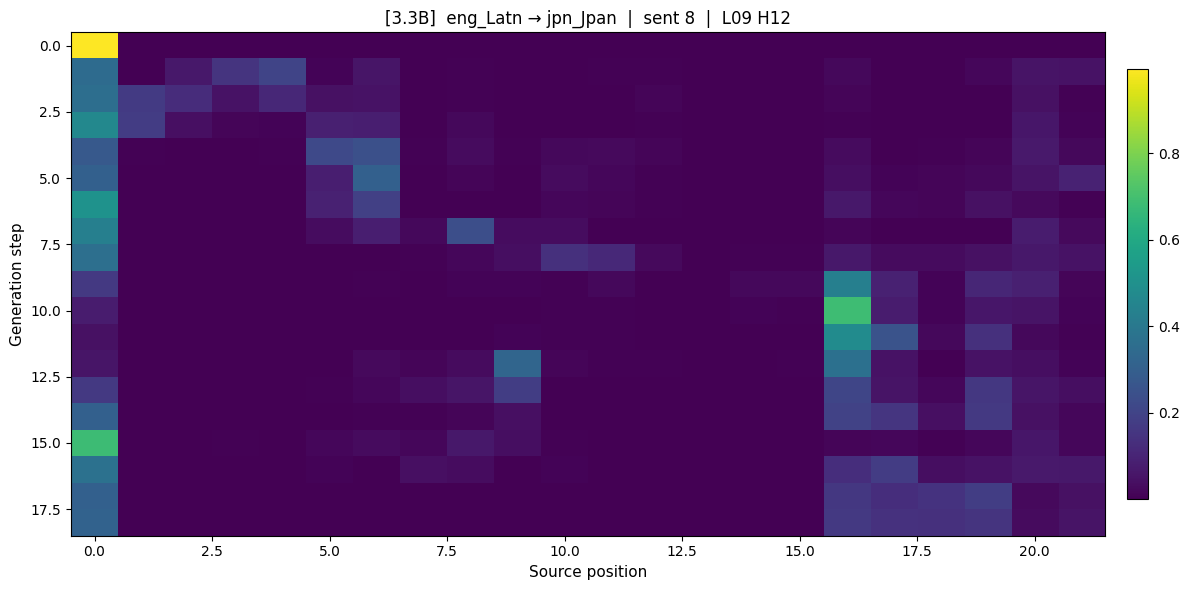

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S8.png


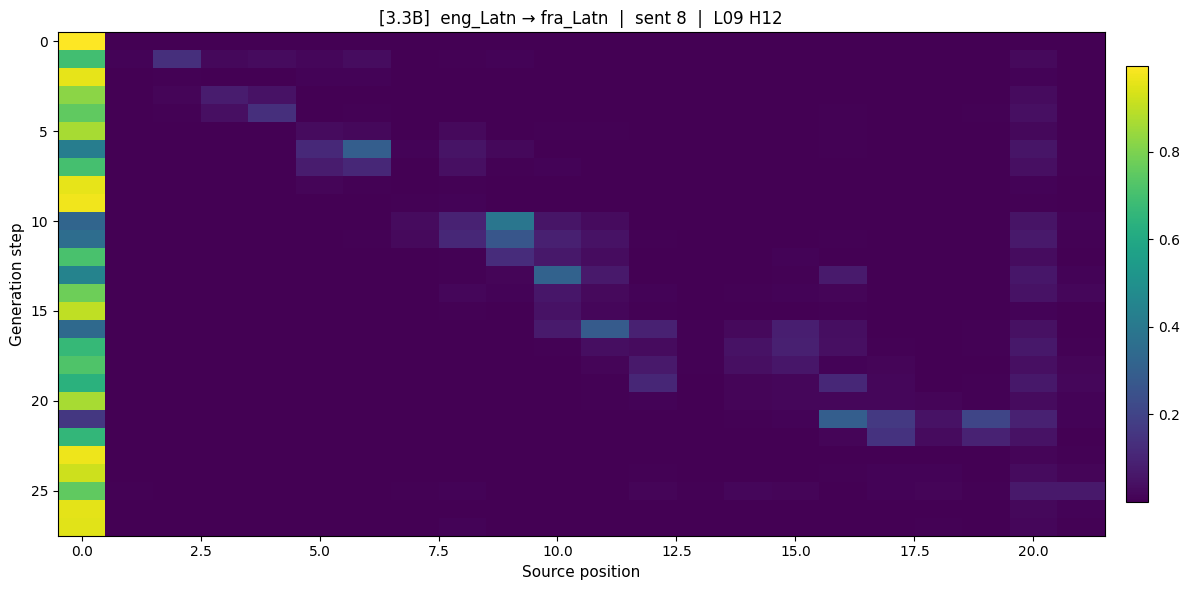

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S9.png


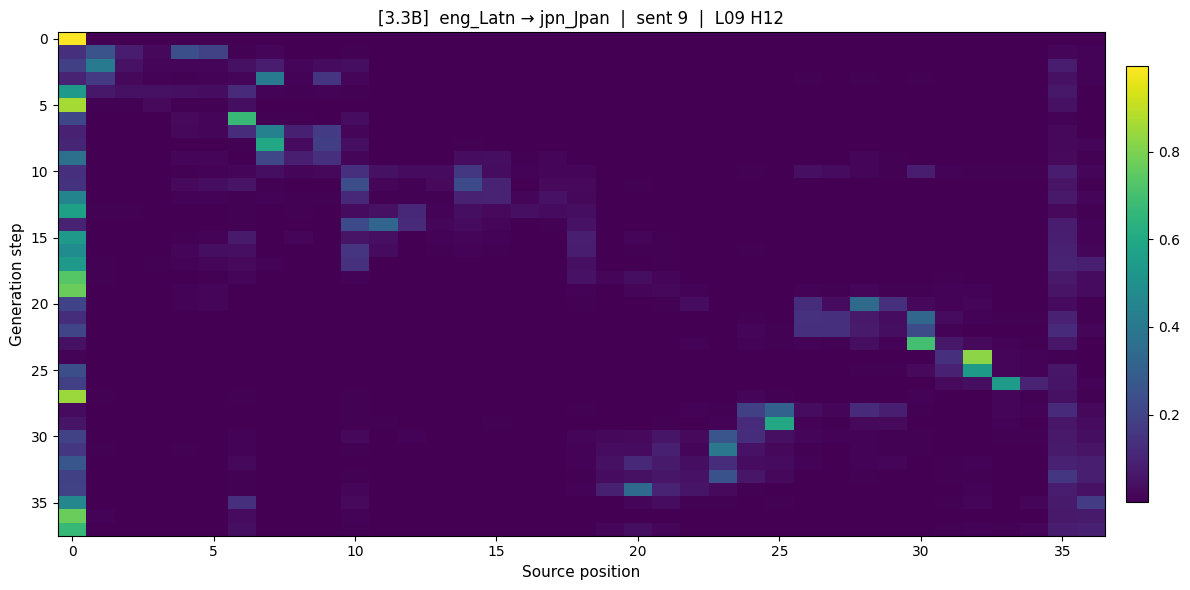

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S9.png


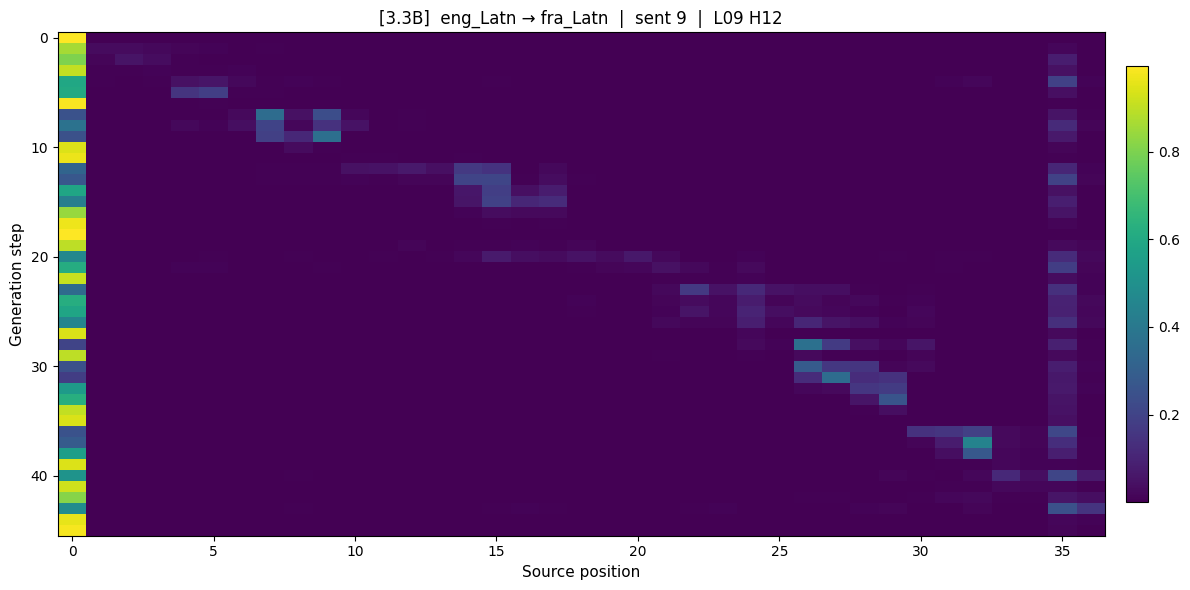

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S10.png


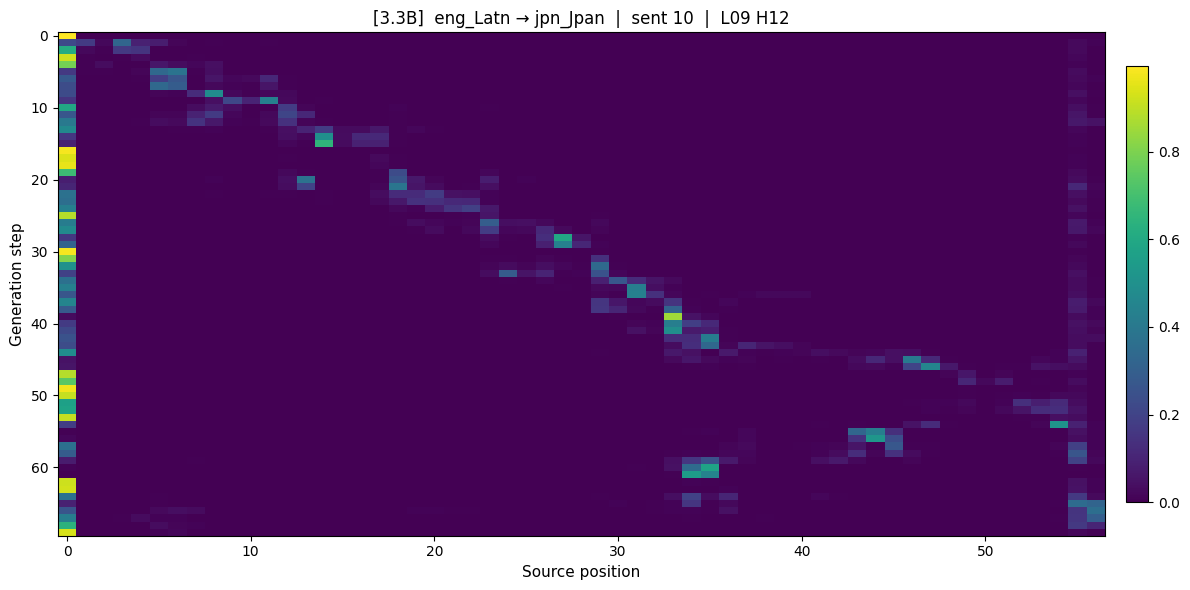

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S10.png


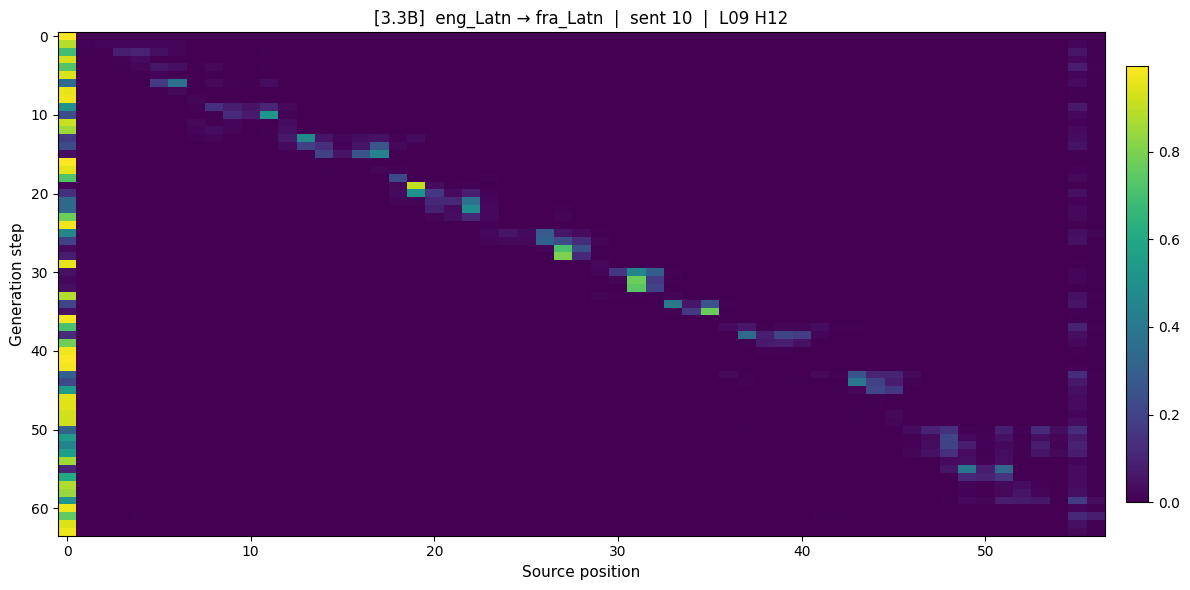

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S11.png


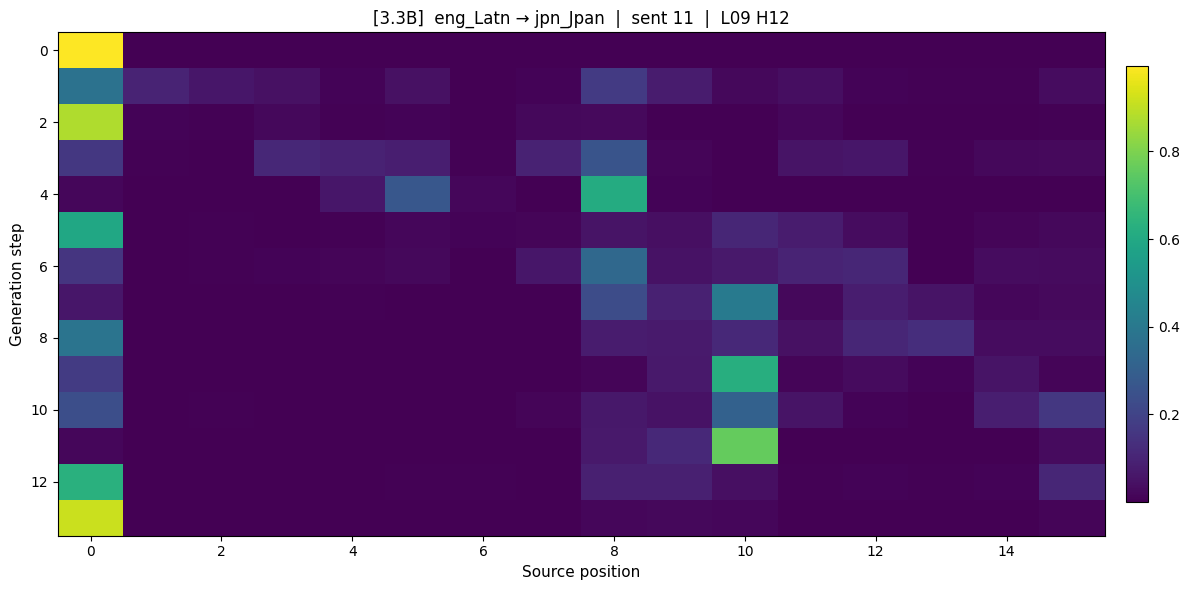

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S11.png


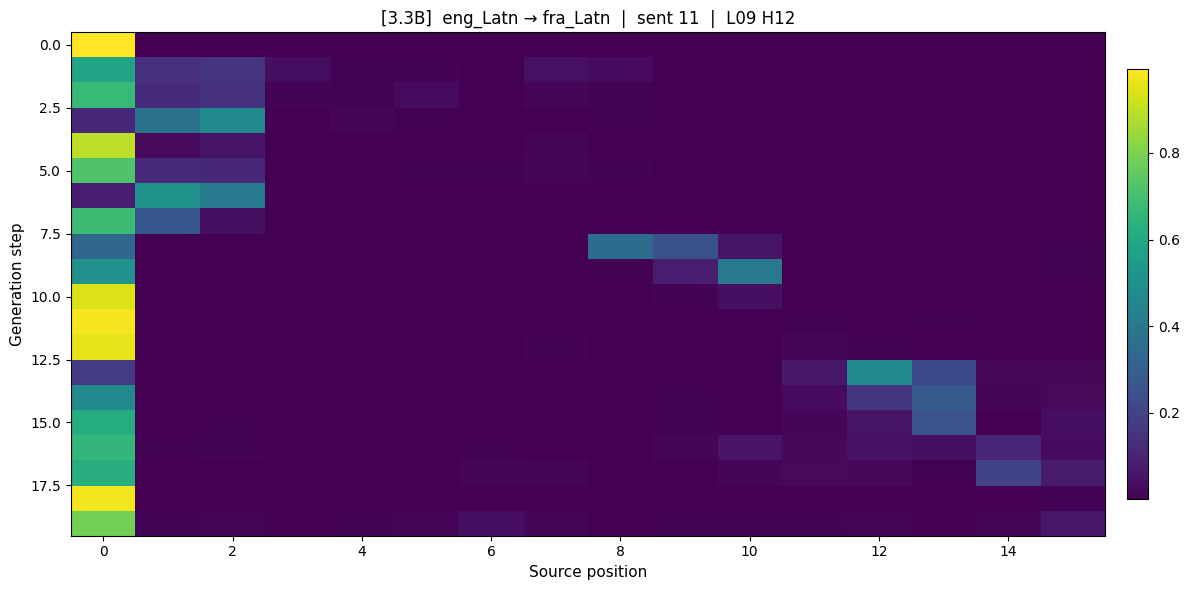

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S12.png


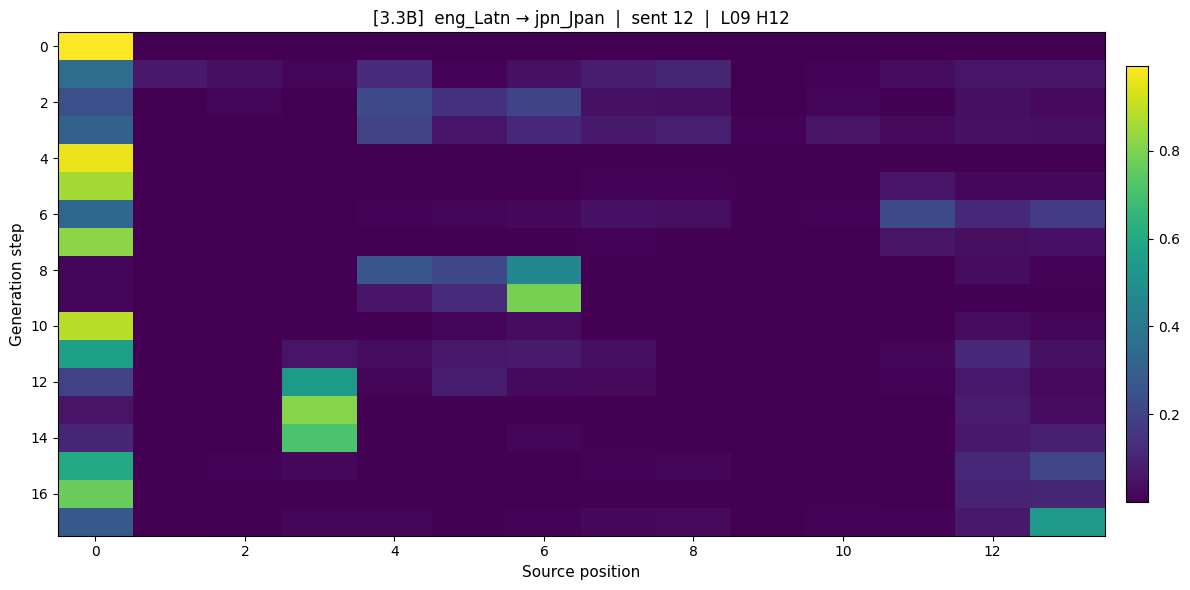

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S12.png


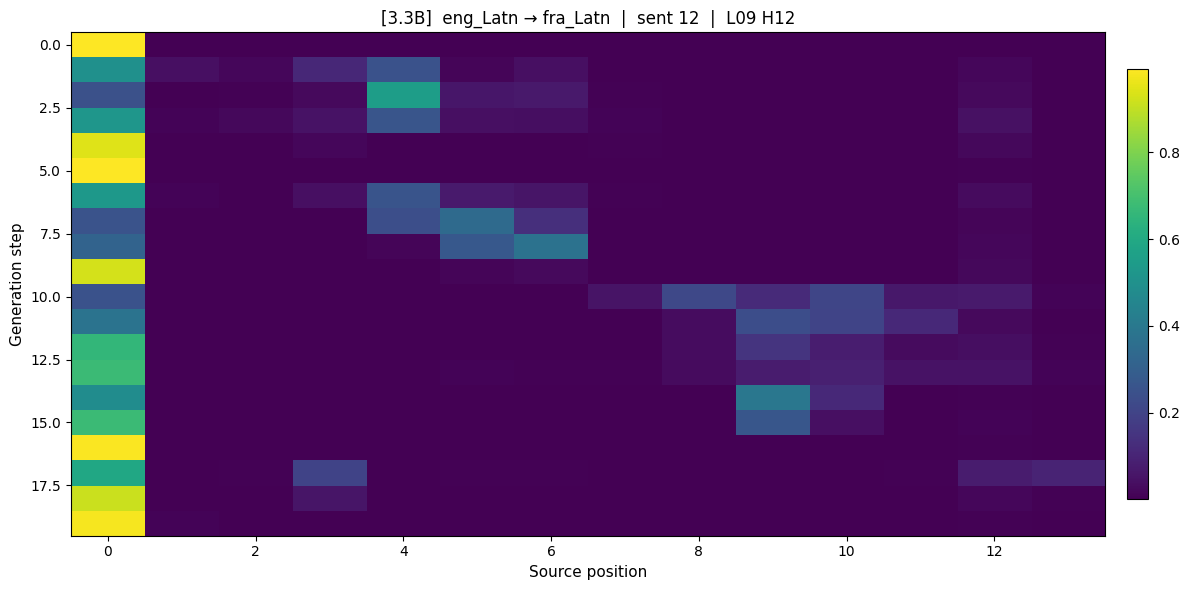

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S13.png


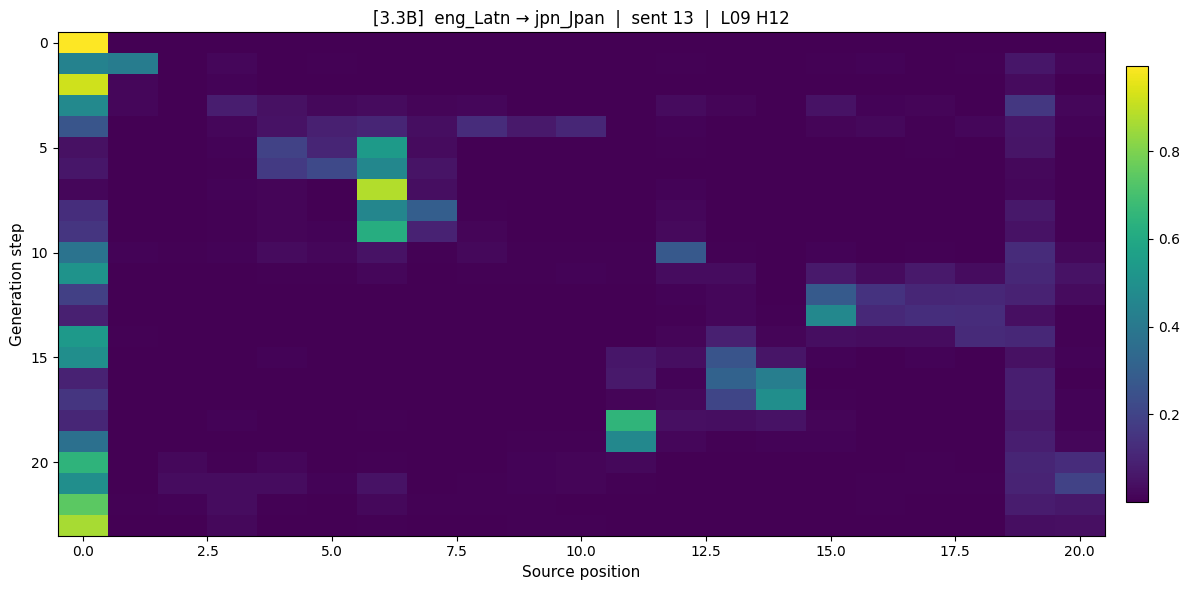

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S13.png


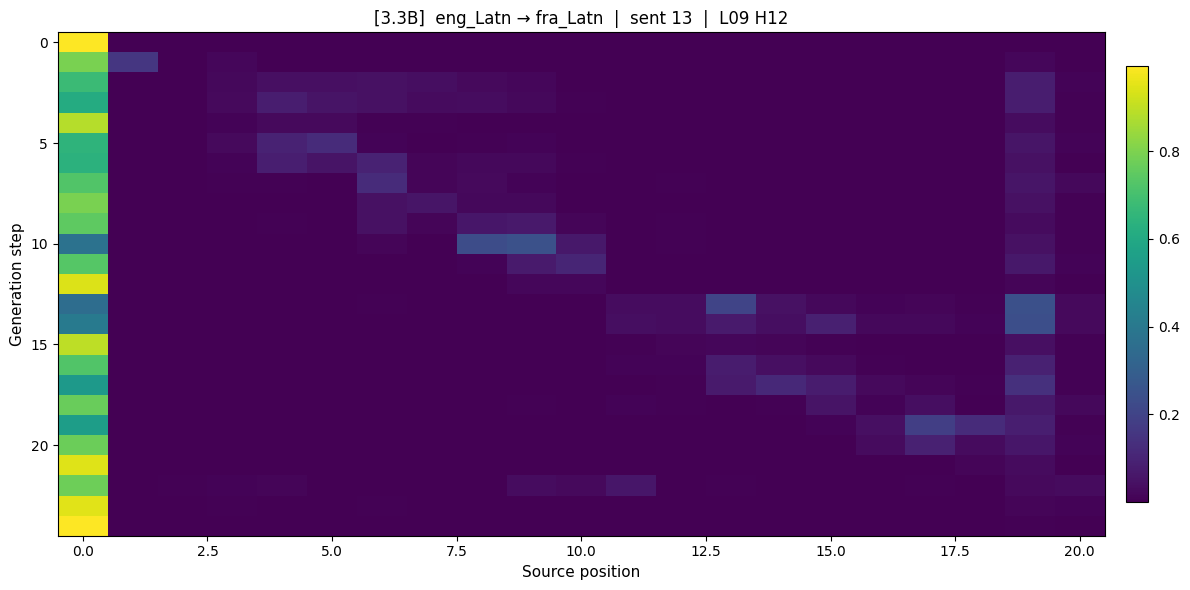

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S14.png


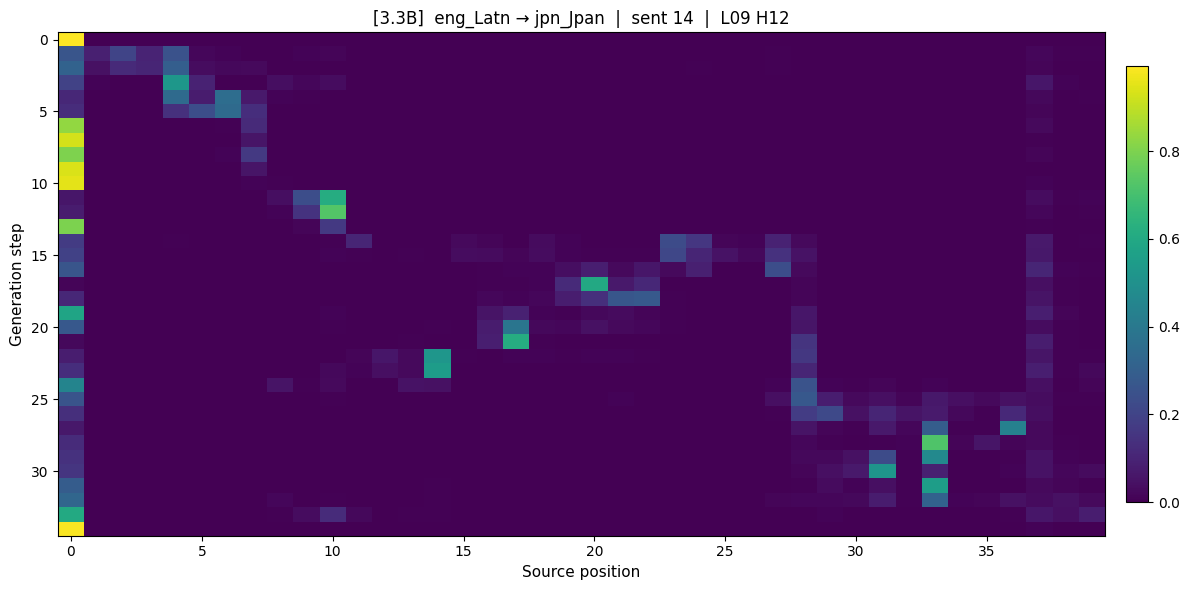

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S14.png


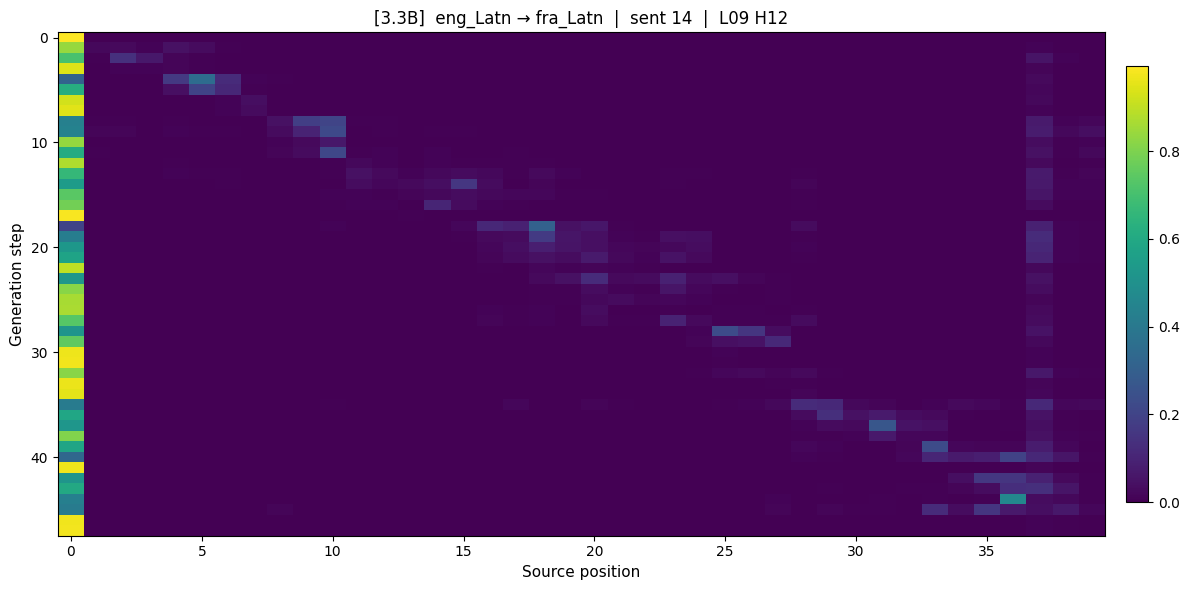

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S15.png


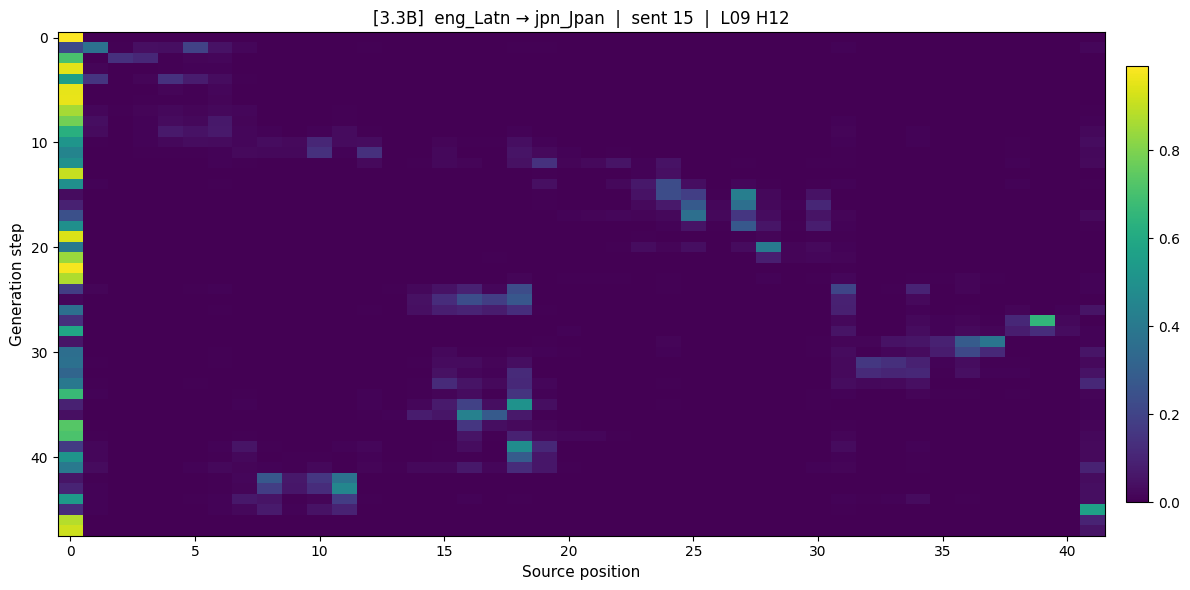

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S15.png


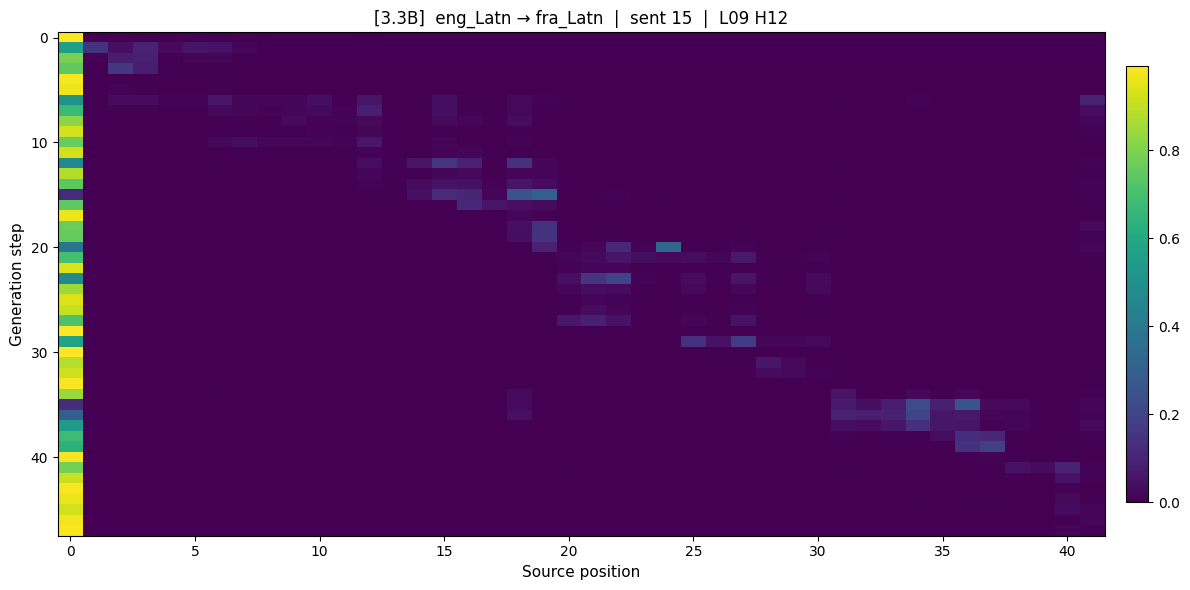

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S16.png


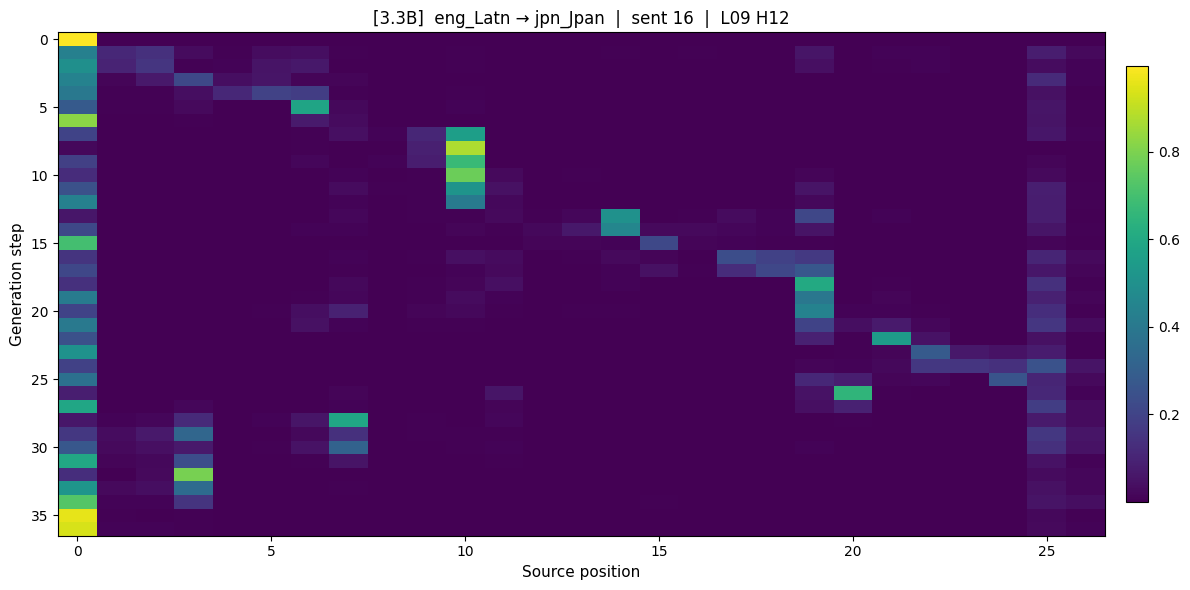

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S16.png


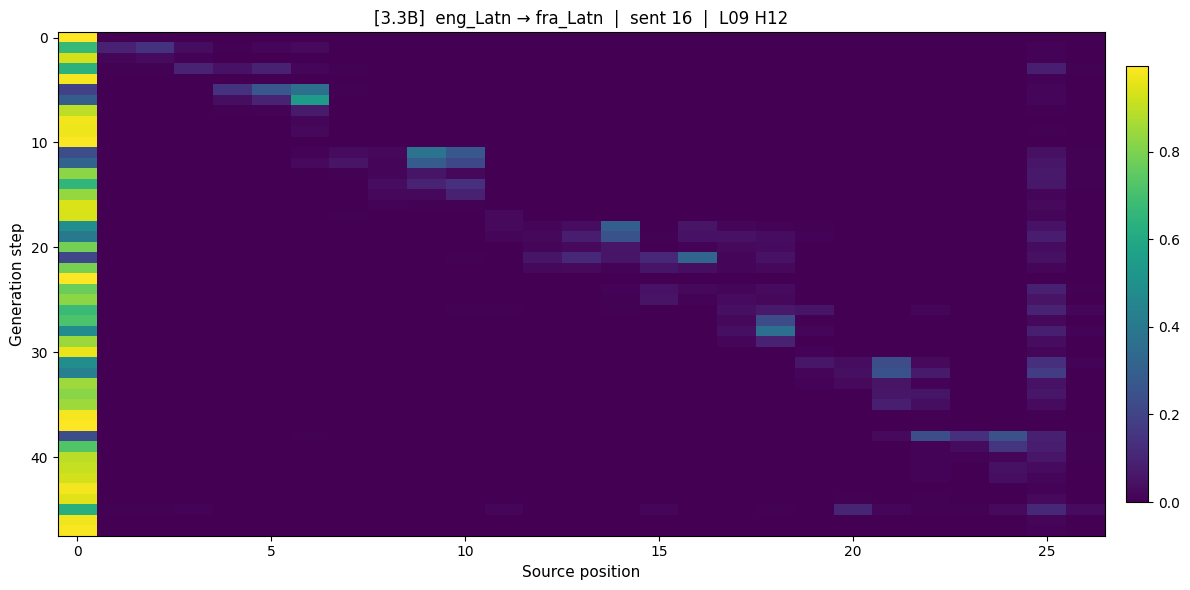

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S17.png


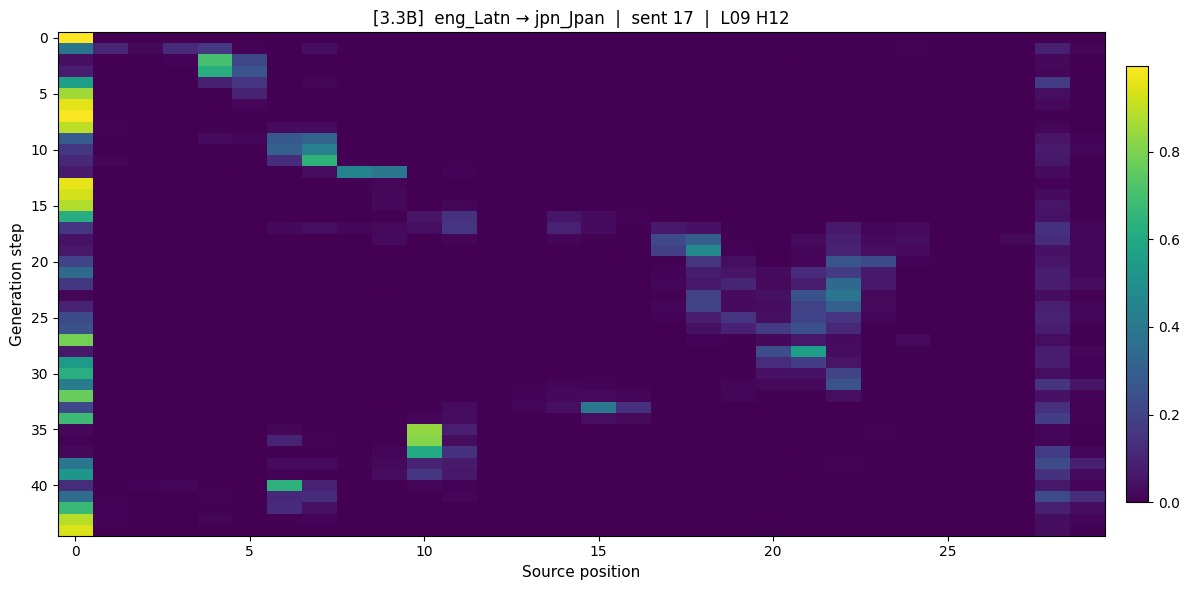

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S17.png


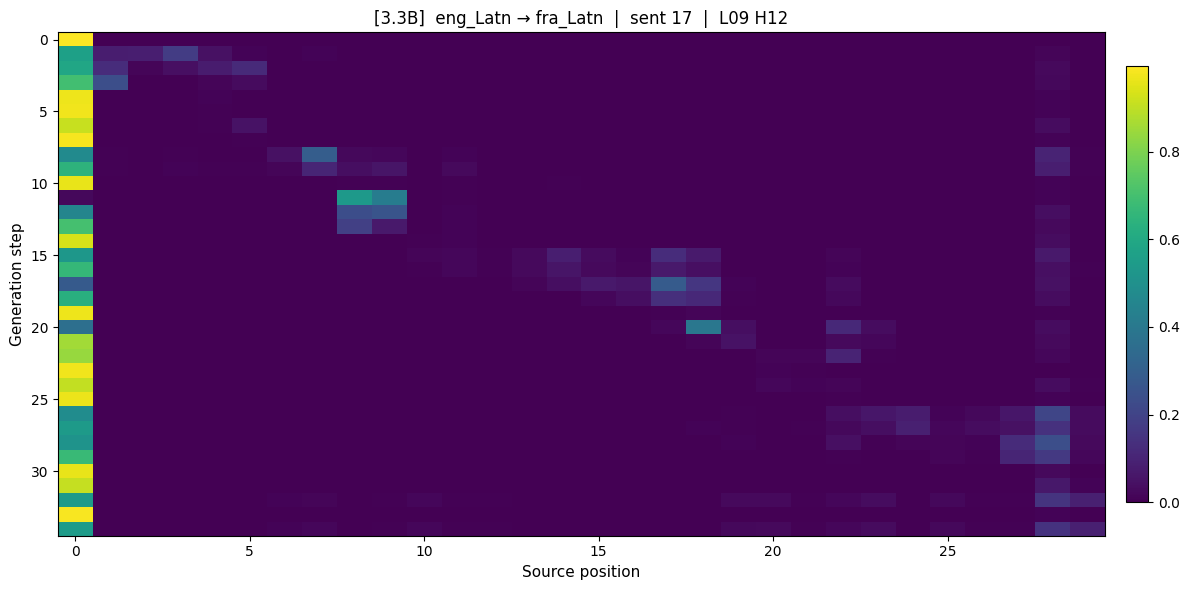

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S18.png


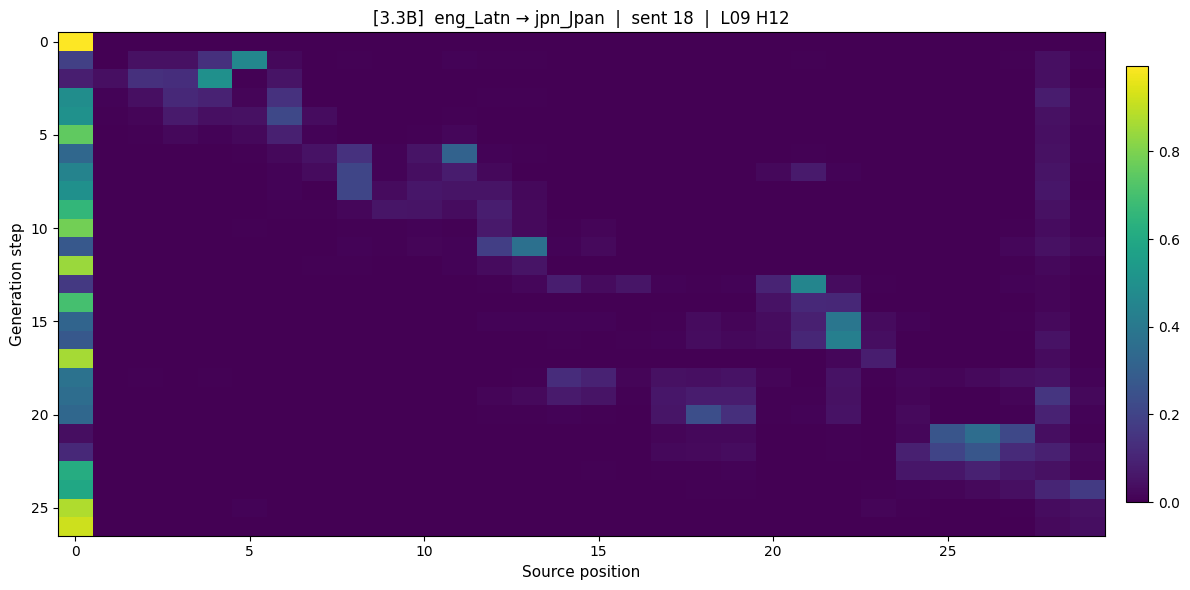

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S18.png


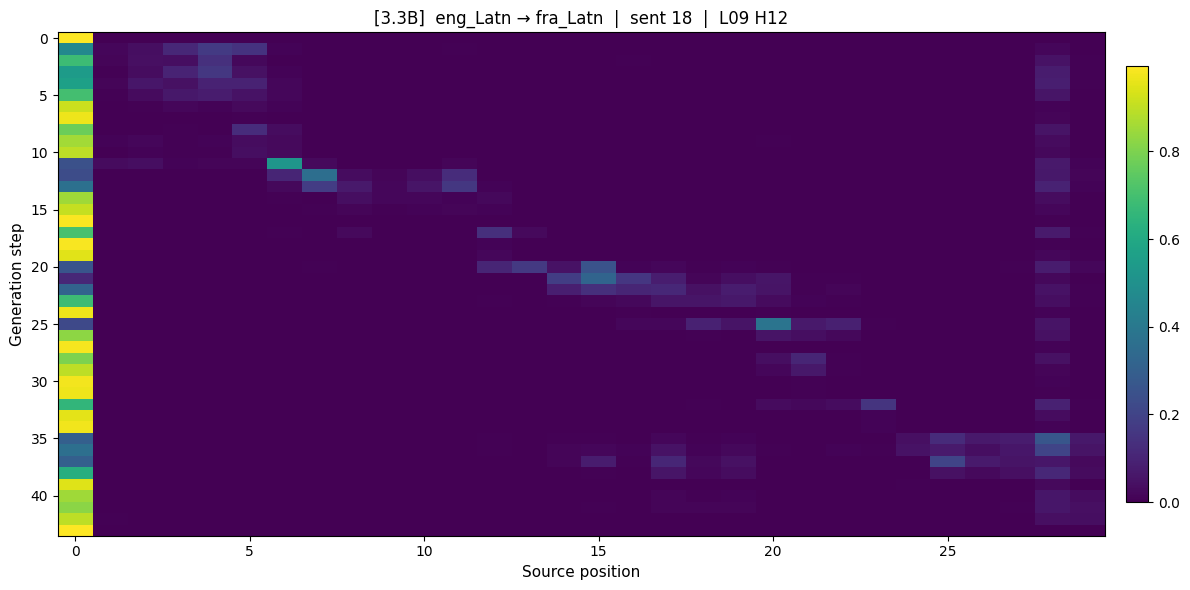

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S19.png


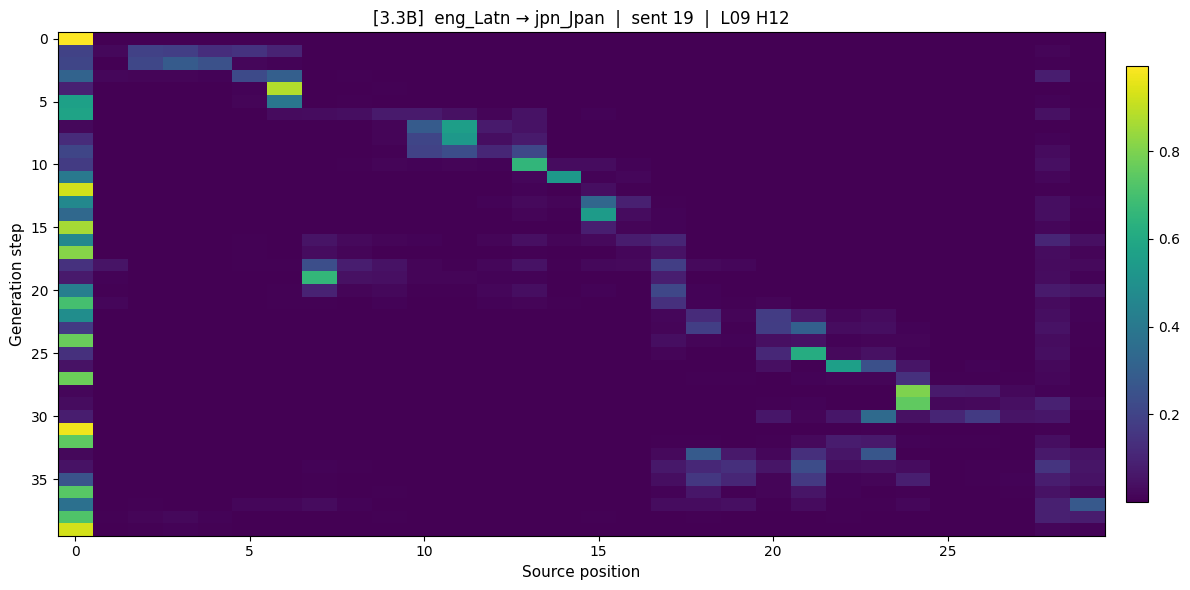

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S19.png


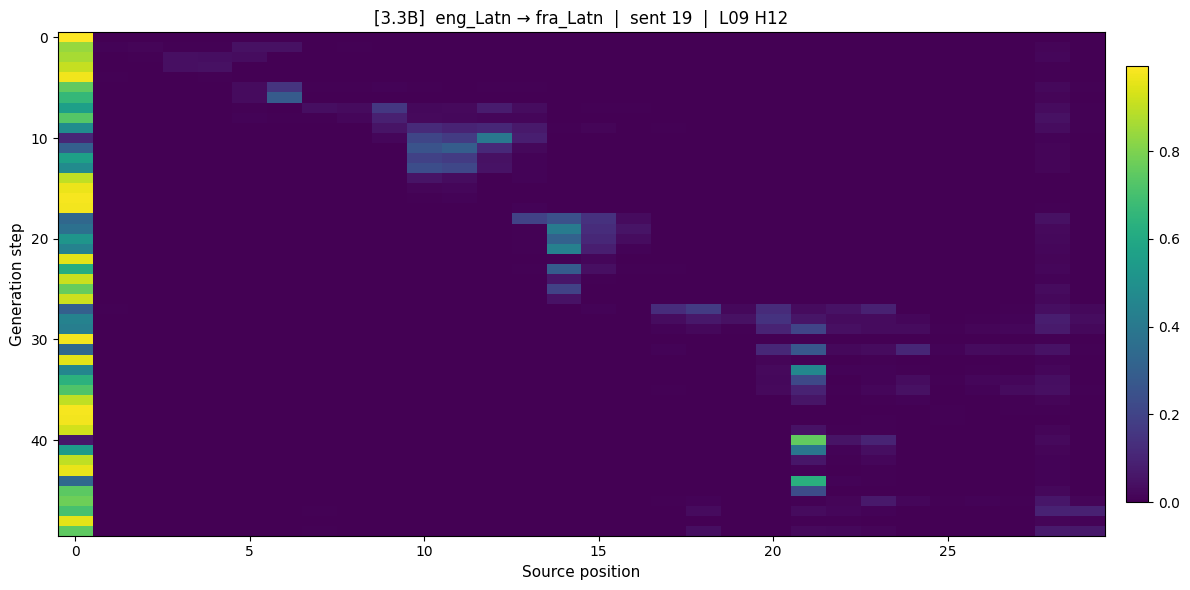

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S20.png


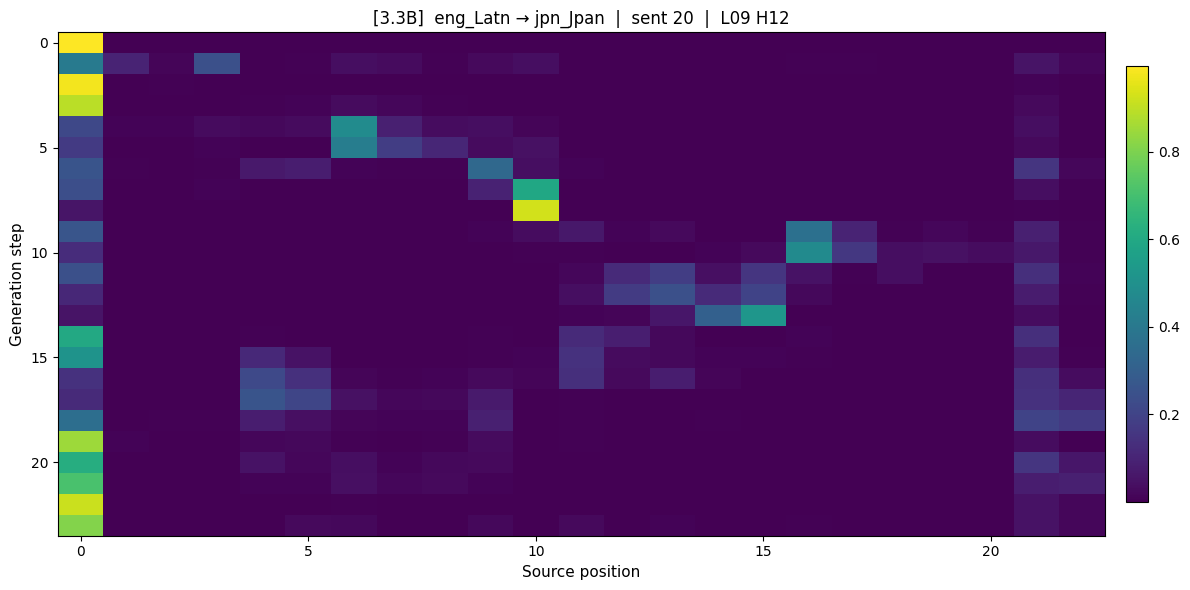

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S20.png


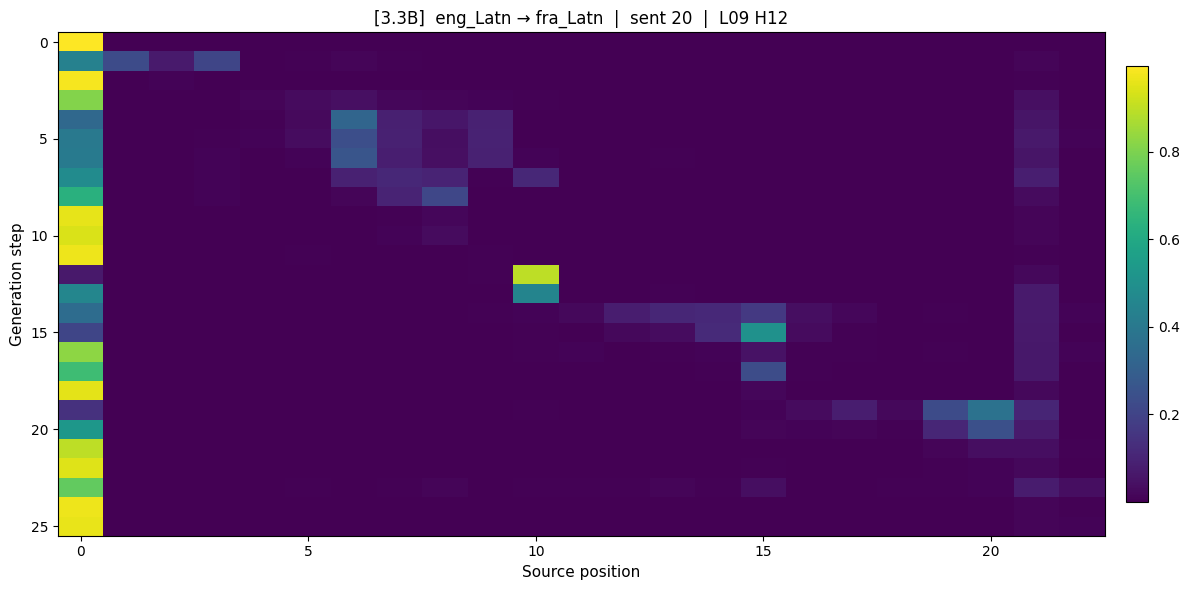

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S21.png


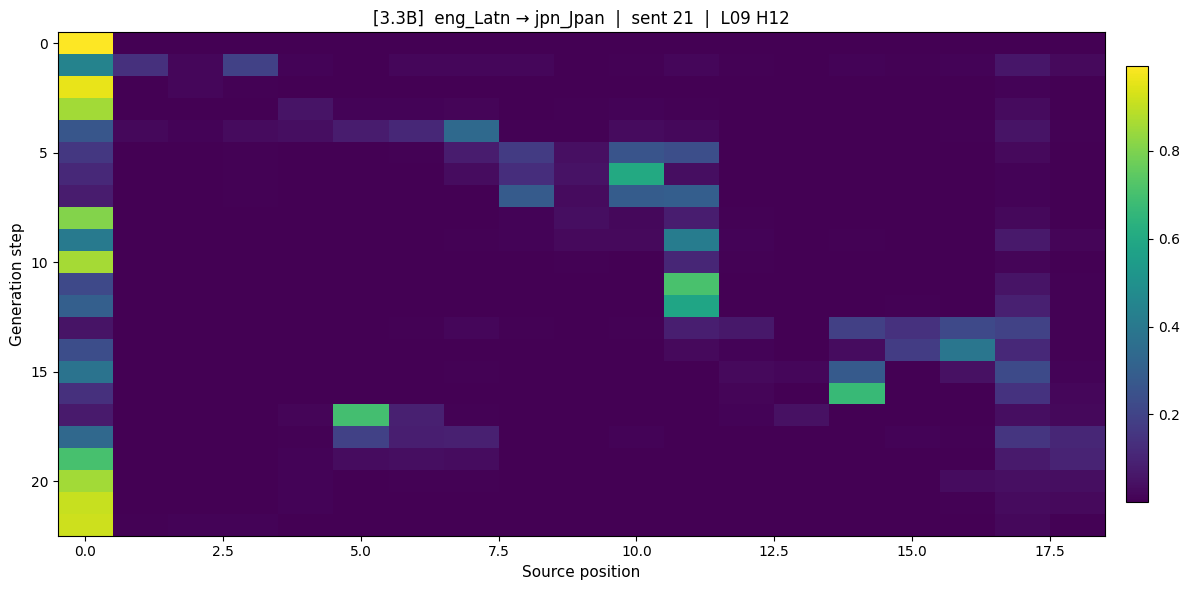

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S21.png


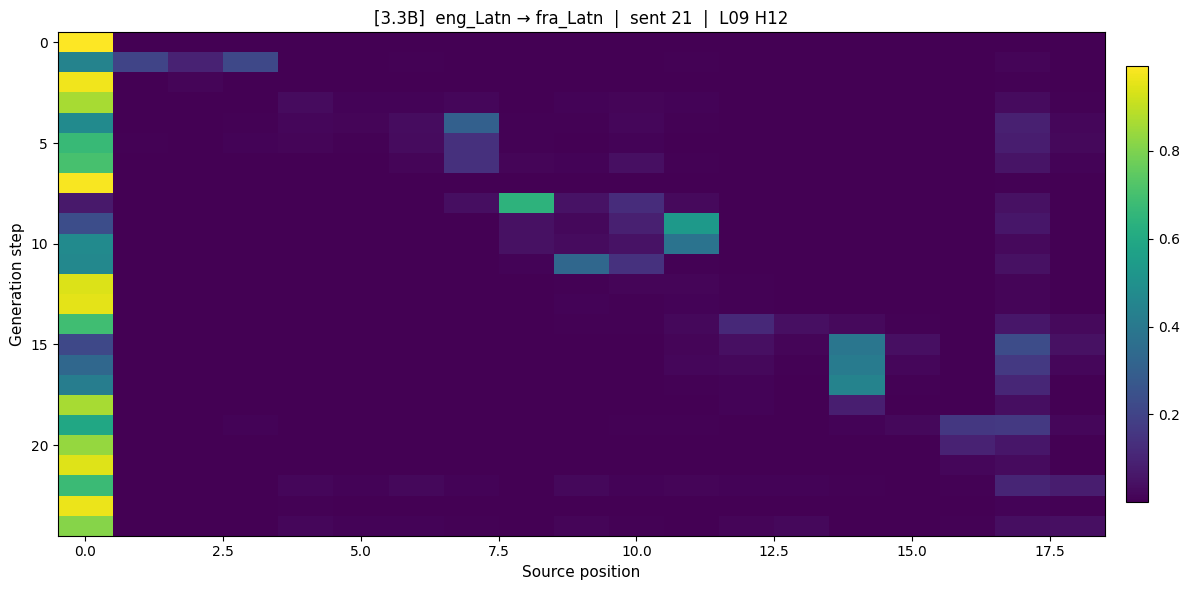

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S22.png


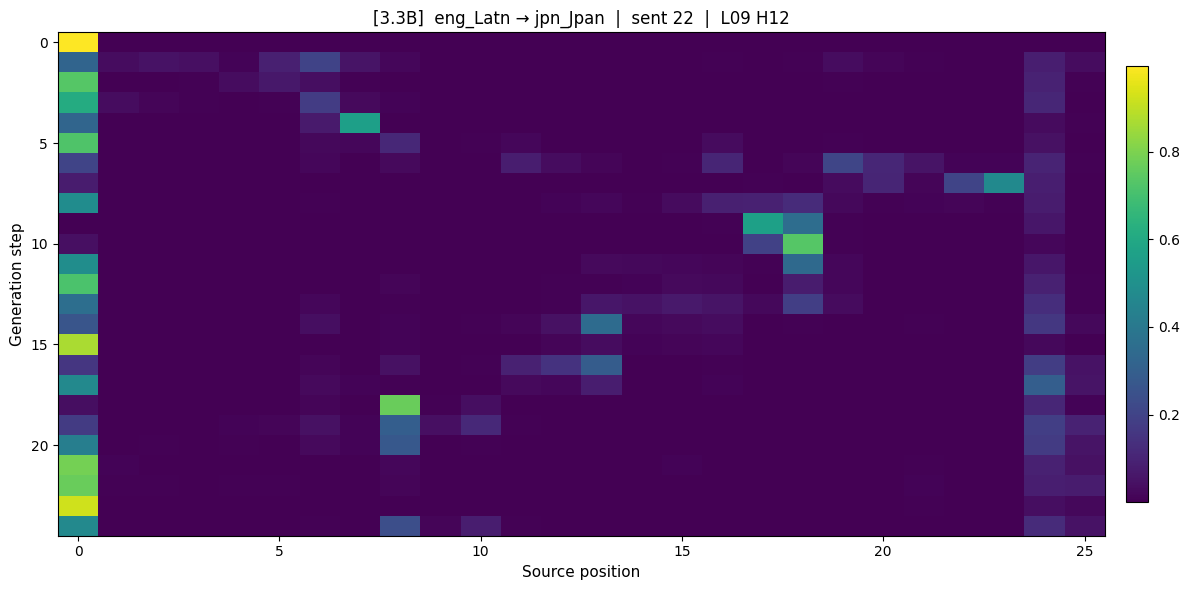

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S22.png


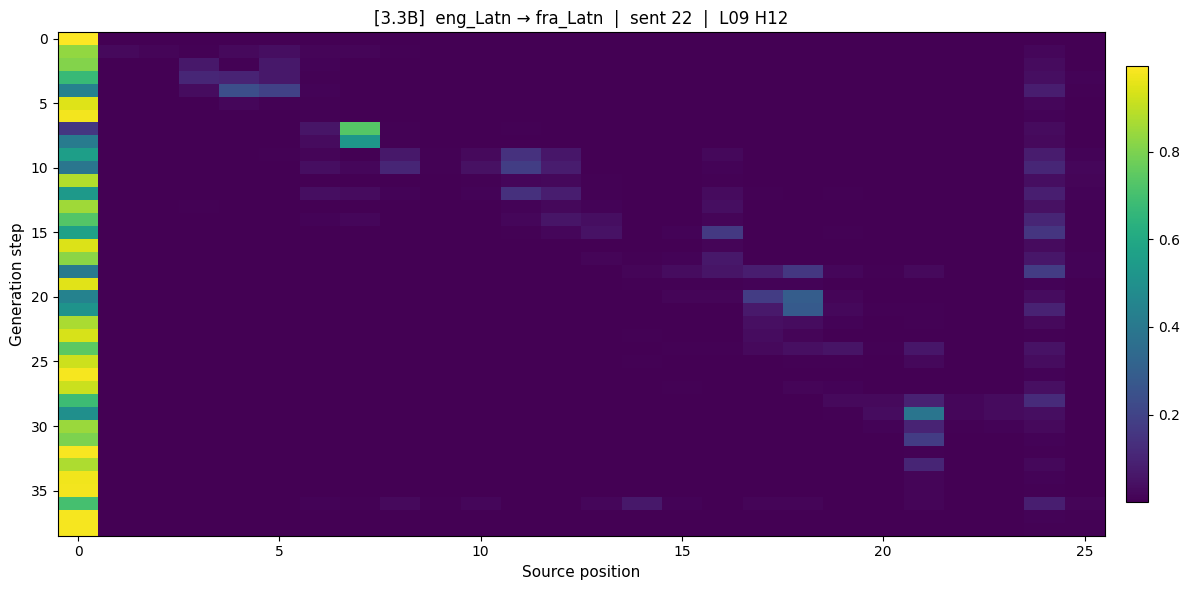

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S23.png


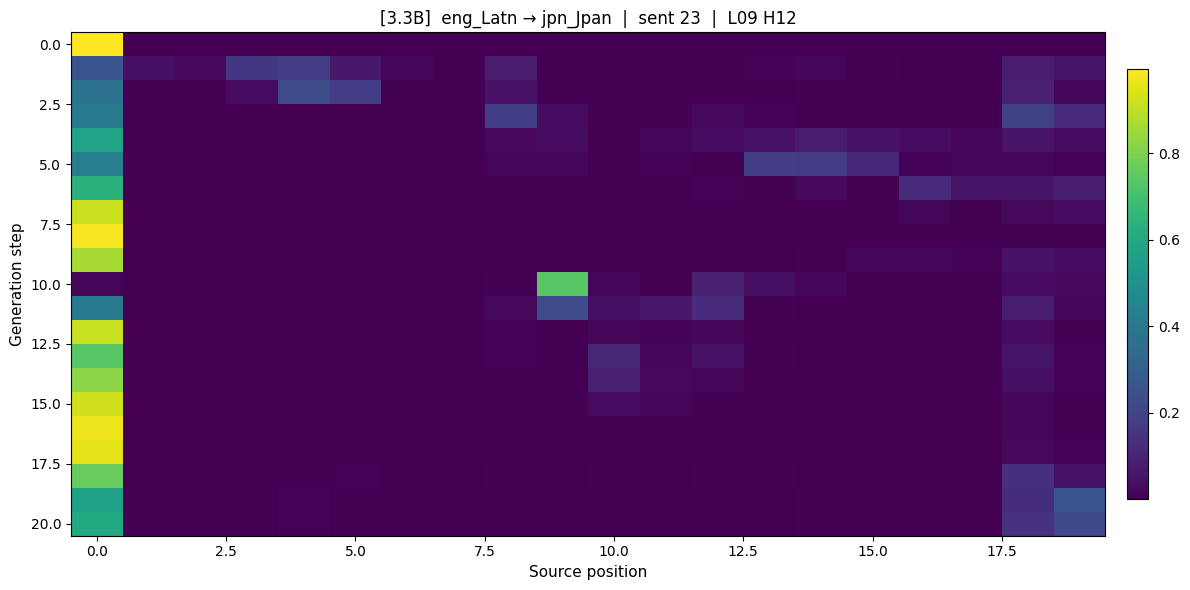

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S23.png


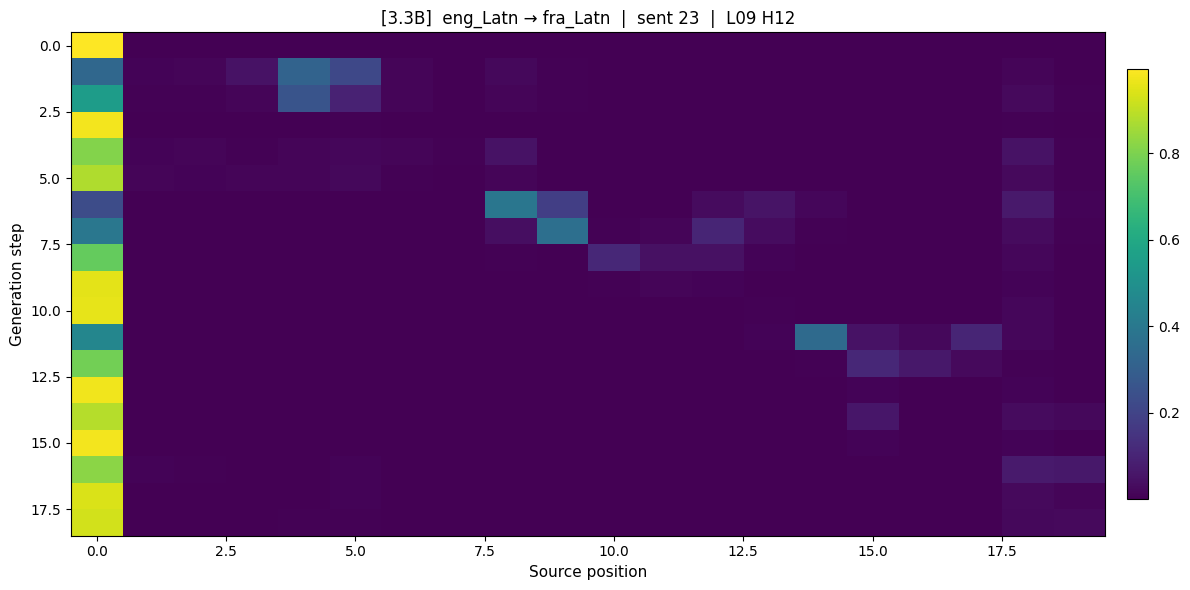

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S24.png


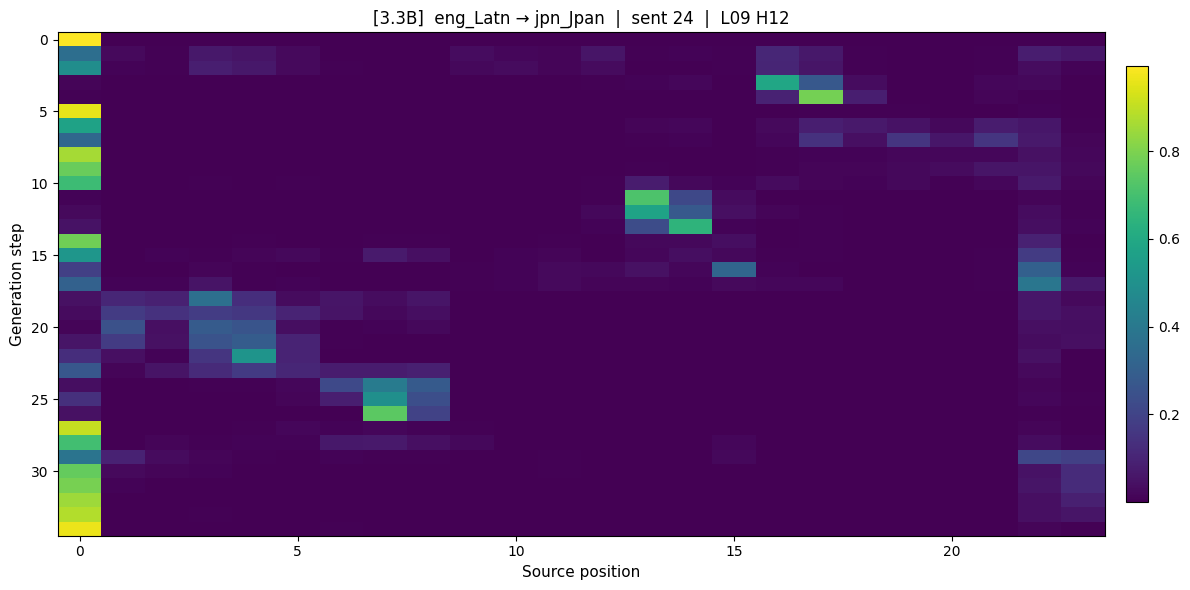

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S24.png


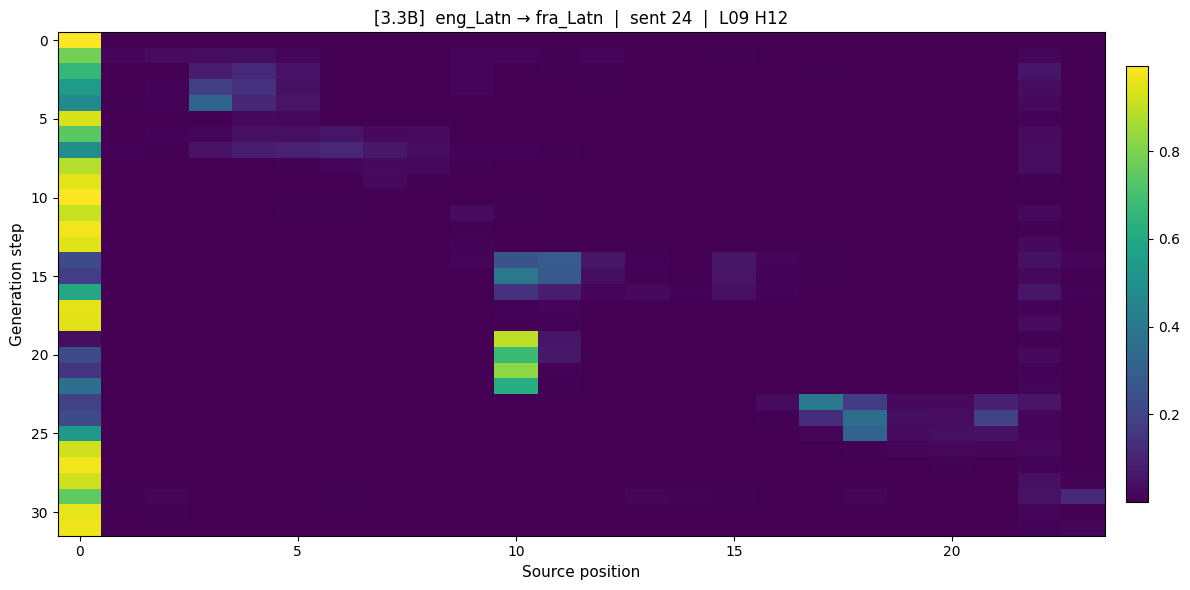

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S25.png


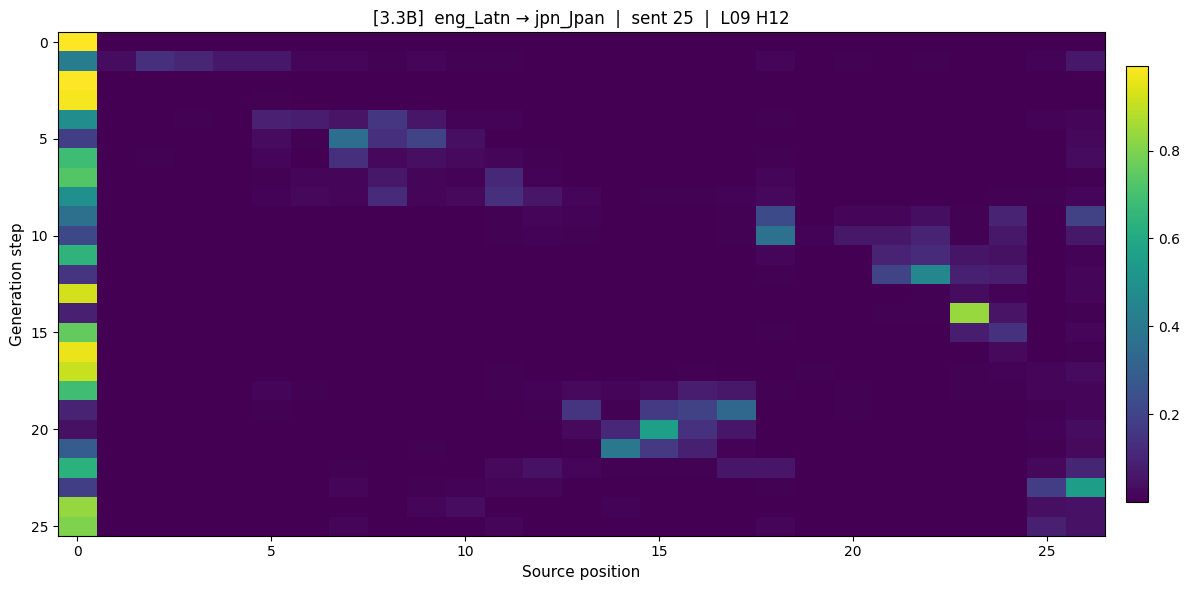

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S25.png


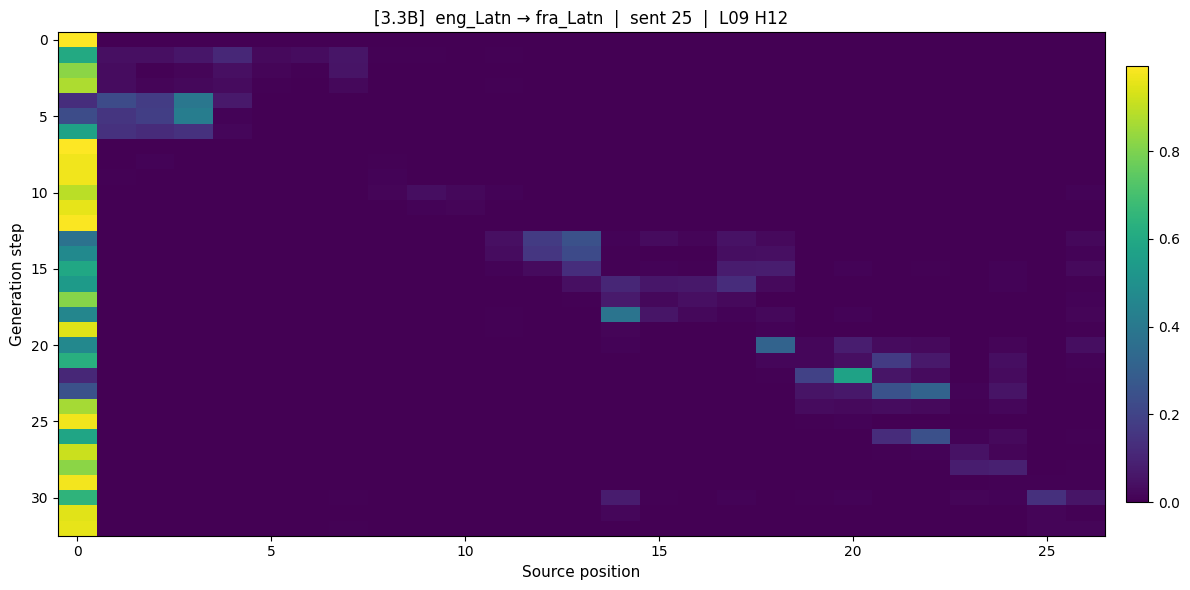

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S26.png


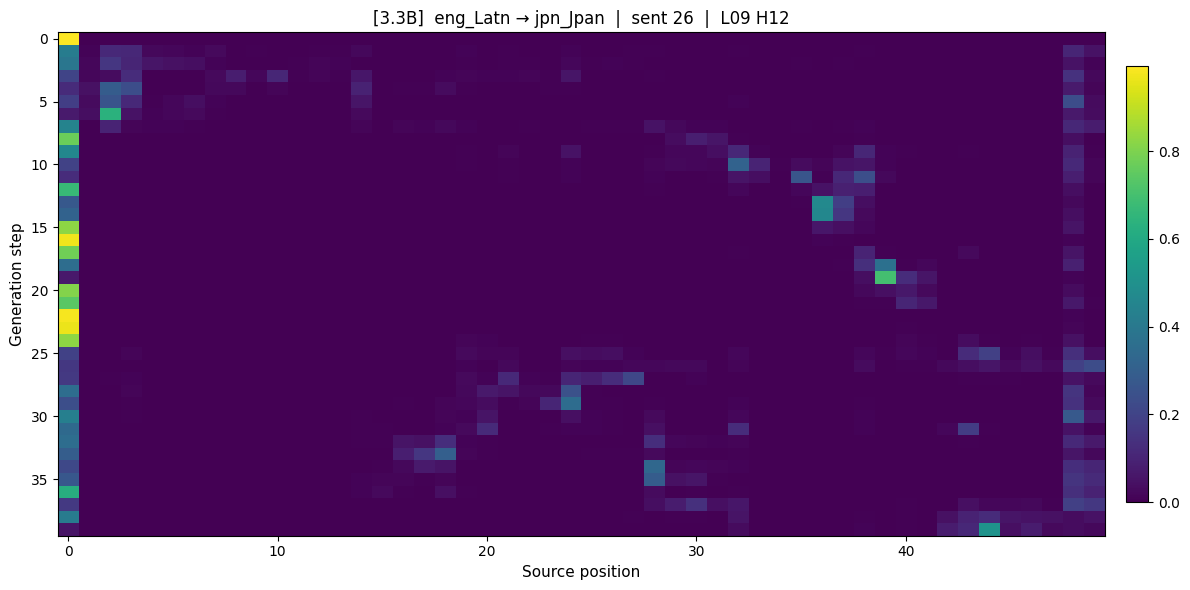

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S26.png


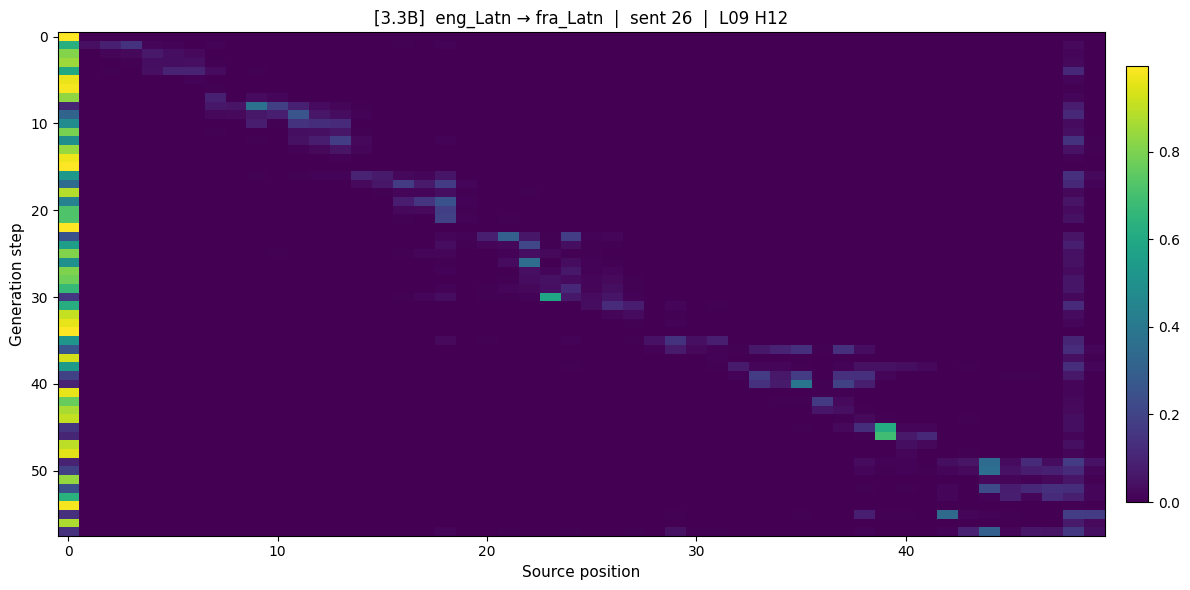

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S27.png


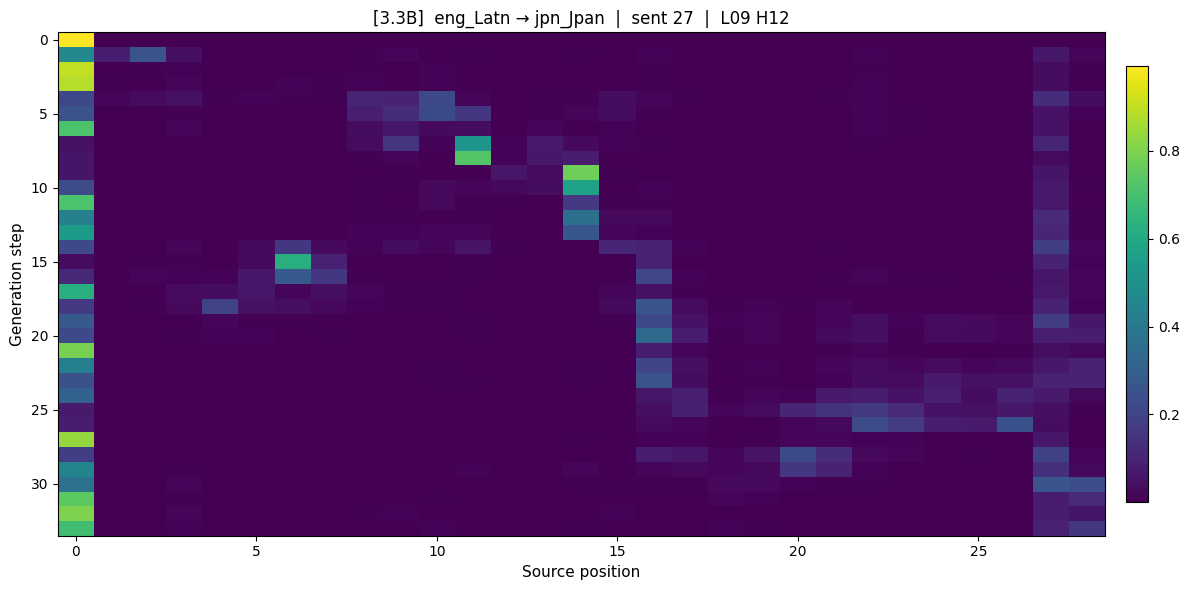

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S27.png


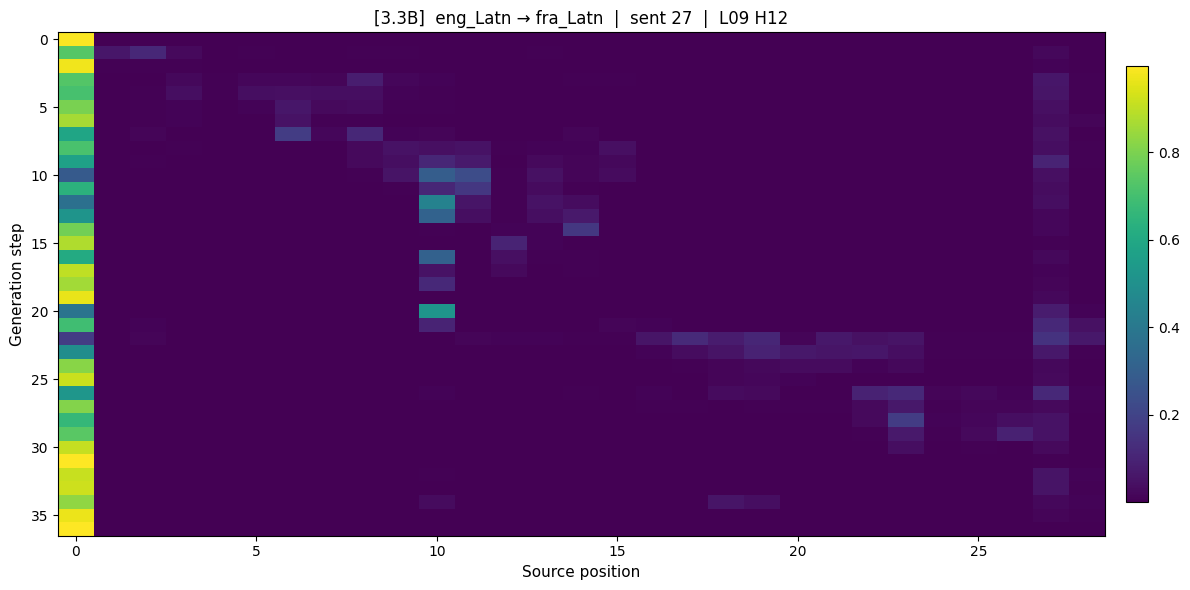

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S28.png


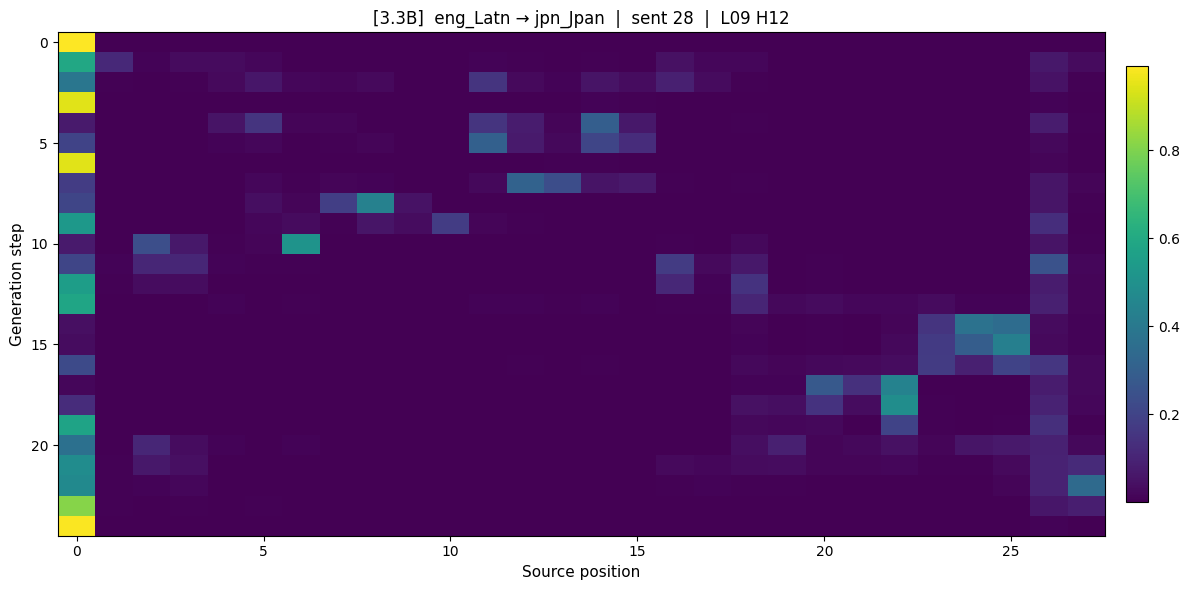

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S28.png


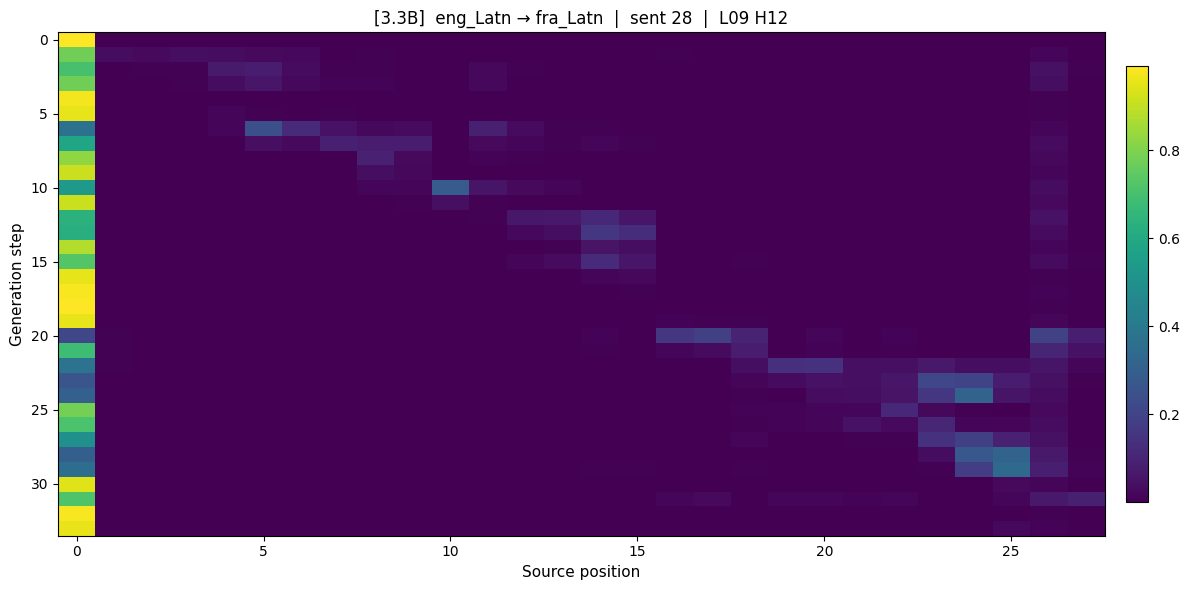

Saved → ./results/maps/3.3B-eng_Latn-jpn_Jpan_L09_H12-S29.png


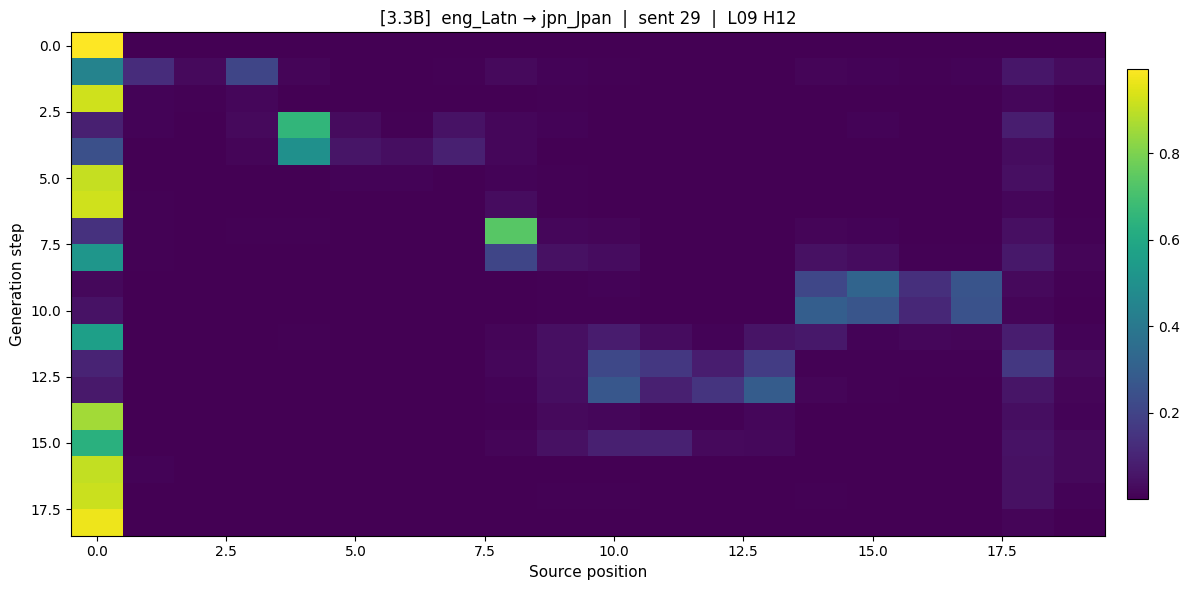

Saved → ./results/maps/3.3B-eng_Latn-fra_Latn_L09_H12-S29.png


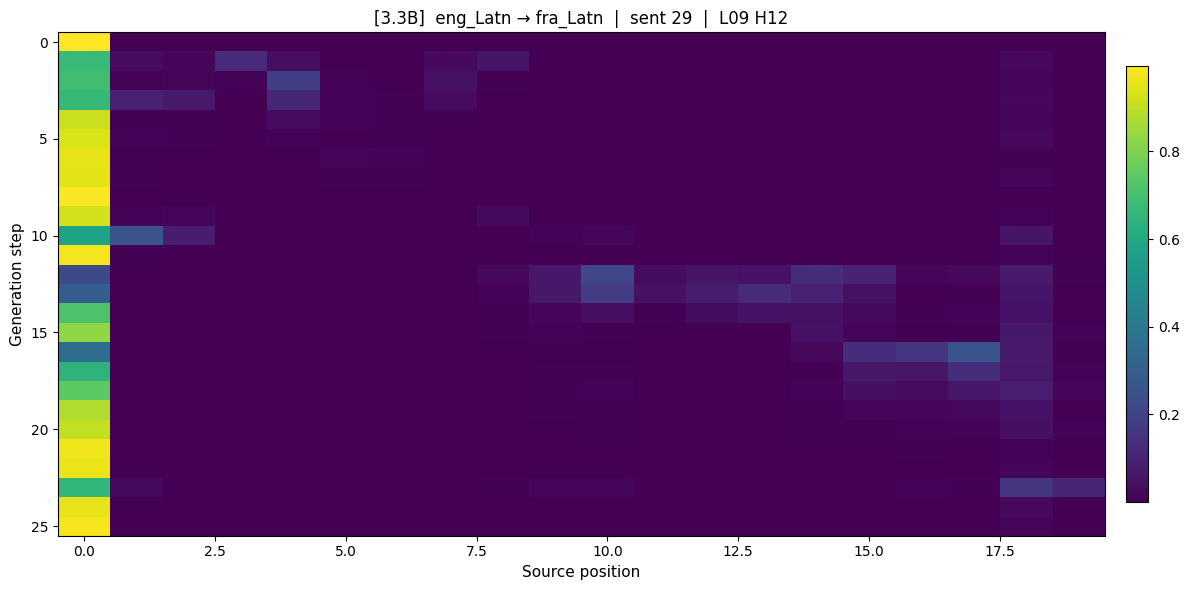

In [10]:
for i in range(30):
    plot_head(
        src_lang  = "eng_Latn",
        tgt_lang  = "jpn_Jpan",
        sent_id   = i,
        layer     = 9,
        head      = 12,
        model     = "3.3B",
        src_text  = None,
        save = True,
    )
    plot_head(
        src_lang  = "eng_Latn",
        tgt_lang  = "fra_Latn",
        sent_id   = i,
        layer     = 9,
        head      = 12,
        model     = "3.3B",
        src_text  = None,
        save = True,
    )